In [1]:
import html
import json
import re
import statistics
import unicodedata

import chromadb
import ftfy
import matplotlib.pyplot as plt
import numpy as np
from charset_normalizer import from_bytes
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter, CharacterTextSplitter, TextSplitter
from unstructured.cleaners.core import (
    clean,  # Удаляет лишние пробелы, пустые строки и нормализует текст
    # Исправляет битые кодировки (MIME / Quoted-Printable)
    # Соединяет случайно разорванные переносами строки
)

with open("filmoskop_kb.json", encoding="utf-8") as f:
    data = json.load(f)
docs = data["docs"]        # 181 раздел базы знаний
queries = data["queries"]  # 66 тестовых запросов с разметкой

print("Разделов:", len(docs), "| Запросов:", len(queries))

W1027 15:48:31.268000 14245 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Разделов: 181 | Запросов: 66


# Этап 1. Аудит и подготовка корпуса

In [2]:
MIN_LENGTH = 30          # Минимальная длина осмысленного документа
JUNK_THRESHOLD = 0.15    # Порог доли мусорных символов

def junk_ratio(text):
    if not text:
        return 0.0
    # Мусор: всё, что не буква, не цифра, не пробел
    # и не базовый знак препинания
    junk = re.findall(r"[^\w\s.,!?;:()«»—-]", text)
    return len(junk) / len(text)

def is_valid_text(raw_text: str) -> bool:
    stripped = raw_text.strip()
    if len(stripped) == 0:
        return False
    if len(stripped) < MIN_LENGTH:
        return False
    ratio = junk_ratio(stripped)
    if ratio > JUNK_THRESHOLD:
        return False
    return True


* Здесь и далее считаем, что "мусорным содержимым" текста является всё, что не буква, не цифра, не пробел.
* Корректным текстом для дальнейшей обработки и нормализации считаем тексты, у которых доля "мусора" не выше 0.15 и длина не меньше чем 30 символов.

Посчитаем среднюю долю "мусорного" содержимого в исходных текстах и долю корректных текстов.

In [3]:
mean_junk_ratio = np.mean([junk_ratio(doc["raw"]) for doc in docs])
valid_docs_share = sum(is_valid_text(doc["raw"]) for doc in docs) / len(docs)
print(f"Средняя доля мусорного содержимого в текстах набора: {mean_junk_ratio * 100:.2f}%")
print(f"Доля корректных документов в наборе: {valid_docs_share * 100:.2f}%")

Средняя доля мусорного содержимого в текстах набора: 3.43%
Доля корректных документов в наборе: 89.50%


Выведем тексты некорректных документов для понимания проблем

In [4]:
for doc in docs:
    if is_valid_text(doc["raw"]):
        continue
    print(f"Doc ID: {doc["doc_id"]}, length: {len(doc["raw"])}{"-" * 43}\n\t{doc["raw"][:60]}\n")

Doc ID: 22, length: 2961-------------------------------------------
	ÐÐ±Ð¾Ð·Ð½Ð°ÑÐµÐ½Ð¸Ðµ 5.1 Ð¾Ð¿Ð¸ÑÑÐ²Ð°ÐµÑ ÑÐ°ÑÐºÐ»Ð°Ð´

Doc ID: 38, length: 847-------------------------------------------
	ÐÐ±ÑÐµÐ´Ð¸Ð½Ð¸ÑÑ Ð´Ð²Ð° Ð°ÐºÐºÐ°ÑÐ½ÑÐ° Â«Ð¤Ð¸Ð»ÑÐ¼Ð¾Ñ

Doc ID: 43, length: 860-------------------------------------------
	Ð£ Ð¼Ð½Ð¾Ð³Ð¸Ñ ÑÐ¸Ð»ÑÐ¼Ð¾Ð² Ð¸ ÑÐµÑÐ¸Ð°Ð»Ð¾Ð² ÐµÑÑÑ 

Doc ID: 46, length: 604-------------------------------------------
	ÐÑÐ°ÑÐºÐ°Ñ Ð¿Ð°Ð¼ÑÑÐºÐ° Ð¿Ð¾ Ð¾ÑÐµÐ½ÐºÐ°Ð¼: ÑÑÐ°Ð²Ñ

Doc ID: 54, length: 683-------------------------------------------
	ÐÑÐ»Ð¸ Ð¿ÑÐ¸Ð»Ð¾Ð¶ÐµÐ½Ð¸Ðµ Ð·Ð°Ð²Ð¸ÑÐ°ÐµÑ Ð½Ð° Ð·Ð°ÑÑ

Doc ID: 55, length: 833-------------------------------------------
	ÐÑÐ»Ð¸ Ð½Ðµ Ð¿Ð¾Ð»ÑÑÐ°ÐµÑÑÑ Ð²Ð¾Ð¹ÑÐ¸, Ð½Ð°Ð¶Ð¼Ð¸ÑÐ

Doc ID: 60, length: 843-------------------------------------------
	ï»¿Ð¡ÑÐ°Ð±Ð¸Ð»ÑÐ½Ð¾ÑÑÑ Ð¿ÑÐ¾ÑÐ¼Ð¾ÑÑÐ° ÑÐ¸Ð»ÑÐ½Ð¾ 

Doc ID: 73, length: 3057-------------------------------------------
	# ÐÑÐµÐ½Ð´Ð° Ð¸ Ð¿

С первого взгляда можно сказать, что большая часть проблем связана с кодировкой текста. Есть просто слишком короткие тексты, не несущие никакой пользы (doc id: 153). Есть тексты, в которых осталась HTML разметка. Приступаем к фильтрации.

Для фильтрации будем использовать следующие библиотеки:

1. `ftfy`: для восстановления крякозябр
2. `unstructured`: для того чтобы иметь единый интерфейс для очистки текста
3. `unicodedata`: для нормализации


In [5]:
import re
import unicodedata
import html
import ftfy

def smart_decode(raw_data) -> str:
    """
    Принимает на вход БАЙТЫ или СТРОКУ с неизвестной кодировкой
    и превращает в чистый читаемый текст.
    """
    if not raw_data:
        return ""

    # 1. Если пришли байты — определяем кодировку через charset-normalizer
    if isinstance(raw_data, bytes):
        match = from_bytes(raw_data).best()
        if match:
            text = str(match)
        else:
            # Фолбэк на случай неудачи
            text = raw_data.decode('utf-8', errors='ignore')
    else:
        text = raw_data

    # 2. Лечим «кракозябры» (можибэйк) с помощью ftfy.
    text = ftfy.fix_text(text)

    return text

def normalize_text(text):
    # Приводим юникод к единой форме NFC
    text = unicodedata.normalize("NFC", text)
    # Склеиваем слово, разорванное переносом строки
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)
    # Неразрывные и нулевой ширины пробелы -> обычный пробел
    text = text.replace("\N{NO-BREAK SPACE}", " ")
    text = text.replace("\N{ZERO WIDTH SPACE}", " ")

    # Схлопываем только горизонтальные пробелы (без \n)
    text = re.sub(r"[ \t]+", " ", text)
    # Убираем пробелы на концах строк, но сохраняем сами строки
    text = "\n".join([line.strip() for line in text.splitlines()])

    return text.strip()

def clean_text_for_rag(raw_text: str) -> str:
    """
    Техническая очистка текста: исправление кодировок,
    удаление HTML-тегов, нормализация пробелов.
    """
    # 1. Восстановление кодировок и базовое очищение
    text = smart_decode(raw_text)
    text = html.unescape(text)

    # 2. Переводим HTML-теги разметки в переносы строк
    text = re.sub(r'<[^>]+>', '\n', text)

    # 3. Удаление веб-мусора
    text = re.sub(r'^\s*\w+\s*(?:→|->|>)\s*\w+.*$', '', text, flags=re.MULTILINE)
    text = re.sub(r'мы используем cookie[^.]+?\.\s*принять', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'\b([\w\s]{5,})\1\b', r'\1', text, flags=re.IGNORECASE)

    # 4. Вызываем библиотеку clean ДО финальной сборки структуры!
    # Так она уберет мусор, но не испортит нашу нормализацию абзацев
    text = clean(text, dashes=True, bullets=True)

    # 5. ПОДГОТОВКА СТРУКТУРЫ АБЗАЦЕВ
    text = re.sub(r'\n{3,}', '\n\n', text)

    # 6. Финальная нормализация и очистка пробелов по строкам
    text = normalize_text(text)

    return text.strip()

def get_semantic_fingerprint(text: str) -> str:
    """
    Создает 'отпечаток' текста для поиска дублей.
    Превращает текст в строку из одних только букв и цифр в нижнем регистре.
    """
    text = text.lower()
    # Оставляем только кириллицу, латиницу и цифры.
    # Это игнорирует пунктуацию, скобки и спецсимволы, что идеально для поиска дублей.
    fingerprint = re.sub(r'[^а-яёa-z0-9]', '', text)
    return fingerprint

def is_invalid_content(doc: dict) -> bool:
    """
    Проверяет, является ли документ 'архивным' или 'внутренним'.
    Проверяет и заголовок, и само содержимое.
    """
    # Ключевые слова, которые делают документ негодным для публичного RAG
    trash_keywords = {"(архив)", "архивный", "архив", "не публиковать", "статья устарела", "служебное"}

    # Проверяем заголовок и raw-текст
    content_to_check = f"{doc.get('title', '')} {doc.get('raw', '')}".lower()

    return any(keyword in content_to_check for keyword in trash_keywords)

def deduplicate_and_clean_corpus(original_docs: list) -> list:
    """
    Основной пайплайн:
    1. Чистит текст.
    2. Группирует по смысловому отпечатку.
    3. Фильтрует мусор и дубликаты.
    4. Выбирает лучший экземпляр.
    """
    # Группировка: { fingerprint: [list_of_docs] }
    groups = {}

    for doc in original_docs:
        # Сначала делаем техническую очистку
        doc['raw'] = clean_text_for_rag(doc['raw'])
        doc['title'] = doc.get('title', '').strip()

        # Создаем отпечаток для группировки
        fingerprint = get_semantic_fingerprint(doc['raw'])

        if not fingerprint:
            continue

        if fingerprint not in groups:
            groups[fingerprint] = []
        groups[fingerprint].append(doc)

    final_clean_docs = []

    for fingerprint, docs_in_group in groups.items():
        if len(docs_in_group) == 1:
            # Если документ уникален, просто проверяем его на "мусорность"
            if not is_invalid_content(docs_in_group[0]):
                final_clean_docs.append(docs_in_group[0])
            continue

        # Если нашли дубликаты (разные объекты с одинаковым смыслом)
        # 1. Сначала отсеиваем все явно 'невалидные' документы
        valid_candidates = [
            d for d in docs_in_group
            if not is_invalid_content(d)
        ]

        if valid_candidates:
            # 2. Из оставшихся валидных выбираем самый информативный (самый длинный)
            best_doc = max(valid_candidates, key=lambda x: len(x.get('raw', '')))
            final_clean_docs.append(best_doc)
        else:
            # Если ВСЕ документы в группе — мусор/архив, мы их все игнорируем
            pass

    return final_clean_docs

Чистим корпус

In [6]:
clean_docs = deduplicate_and_clean_corpus(docs)

Проверяем что было удалено

In [7]:
deleted_doc_titles = set([d["title"] for d in docs]).difference(set([d["title"] for d in clean_docs]))
print(f"Было удалено {len(deleted_doc_titles)} из {len(docs)} документов")
for doc_t in deleted_doc_titles:
    print(f"\t{doc_t}")

Было удалено 31 из 181 документов
	ПИН-код (архив)
	Пробный период (архив)
	Аренда фильмов (архив)
	Скачивание фильмов и сериалов (архив)
	Регламент обработки обращений об ошибках
	Скорость интернета для просмотра (архив)
	Профили в аккаунте (архив)
	Коды ошибок плеера (архив, старая нумерация)
	Шаблоны ответов поддержки: аккаунты
	Тарифы «Фильмоскопа» (архив)
	Годовая подписка (архив)
	Регламент размещения справочных материалов. Приложение 2
	Проверка вёрстки
	Восстановление пароля (архив)
	Как смотреть с телефона на большом экране
	Автопродление подписки (архив)
	Раздел перенесён
	Протокол встречи контент-команды
	Объёмный звук 5.1 (архив)
	Вход на телевизоре по коду (архив)
	Как зарегистрироваться
	Отмена подписки и возврат средств (архив)
	Совместный просмотр (архив)
	Ошибка P-102 (архив)
	Требования для просмотра в 4K (архив)
	Выгрузка по профилям (служебное)
	Раздел справки (архив)
	Привязанные устройства (архив)
	Смена тарифа (архив)
	Способы оплаты (архив)
	Шаблон ответа на обр

In [8]:
mean_junk_ratio = np.mean([junk_ratio(doc["raw"]) for doc in clean_docs])
valid_docs_share = sum(is_valid_text(doc["raw"]) for doc in clean_docs) / len(clean_docs)
print(f"Средняя доля мусорного содержимого в текстах набора: {mean_junk_ratio * 100:.2f}%")
print(f"Доля корректных документов в наборе: {valid_docs_share * 100:.2f}%")

Средняя доля мусорного содержимого в текстах набора: 0.16%
Доля корректных документов в наборе: 98.67%


* Средняя доля мусорного содержимого в текстах набора упала с `3.43%` до `0.16%`
* Доля корректных документов в наборе возросла с `89.50%` до `98.67%`


Посмотрим на оставшиеся некорректные документы

In [9]:
for doc in clean_docs:
    if is_valid_text(doc["raw"]):
        continue
    print(f"Doc ID: {doc["doc_id"]}, length: {len(doc["raw"])}{"-" * 43}\n\t{doc["raw"][:60]}\n")

Doc ID: 153, length: 14-------------------------------------------
	QX 500;2020;да

Doc ID: 156, length: 14-------------------------------------------
	Схема разделов



Осталось только два документа длиной 14 символов. Содержимое этих документов не представляет ценности. Ими можно пренебречь.

Фильтруем выборку

In [10]:
clean_docs = [doc for doc in clean_docs if is_valid_text(doc["raw"])]

Проверяем отсутствие в наборе дублей.

In [11]:
print(f"Есть дубликаты по ID: {len(set([doc["doc_id"] for doc in clean_docs])) != len(clean_docs)}")
print(f"Есть дубликаты по тексту: {len(set([doc["raw"] for doc in clean_docs])) != len(clean_docs)}")

Есть дубликаты по ID: False
Есть дубликаты по тексту: False


Дублей в наборе нет

In [12]:
print(f"Осталось документов после очистки: {len(clean_docs)}")

Осталось документов после очистки: 148


# Этап 2. Чанкинг и эмбеддинги

Нужно определить что из себя представляет содержимое текста. Для начала оценим статистические данные.

In [13]:
sizes = [len(doc["raw"]) for doc in clean_docs]
min_text_size = min(sizes)
median_text_size = statistics.median(sizes)
max_text_size = max(sizes)
print(f"  текстов: {len(clean_docs)}")
print(f"Статистика длины текстов\n  min / медиана / max: \n  {min_text_size} / {median_text_size:.0f} / {max_text_size}")

  текстов: 148
Статистика длины текстов
  min / медиана / max: 
  70 / 684 / 2027


Построим график

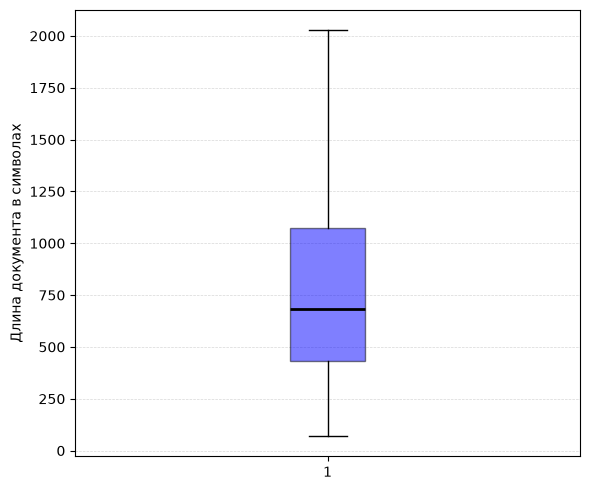

In [14]:
plt.figure(figsize=(6, 5))

# patch_artist=True позволяет раскрасить ящики
# medianprops настраивает линию медианы внутри ящика
box = plt.boxplot(sizes,
                  patch_artist=True,
                  medianprops={'color': 'black', 'linewidth': 2})

# Раскрашиваем ящики в разные цвета для наглядности
colors = ['blue']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)  # Делаем цвета приятнее с помощью прозрачности

plt.ylabel('Длина документа в символах')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Возьмём и рассмотрим (визуально) три примера: текст с минимальной длиной, средний текст (около медианы), и текст с максимальной длиной.

In [15]:
sample_min_doc = next((doc for doc in clean_docs if len(doc["raw"]) == min_text_size), None)
sample_max_doc = next((doc for doc in clean_docs if len(doc["raw"]) == max_text_size), None)
sample_med_doc = min(clean_docs, key=lambda doc: abs(len(doc["raw"]) - median_text_size)) # Выбираем текст с наименьшей разницей в длине с медианой

In [16]:
for doc in [sample_min_doc, sample_med_doc, sample_max_doc]:
    print(f"Doc ID: {doc["doc_id"]}, title: `{doc["title"]}`, length: {len(doc["raw"])}, format: {doc["format"]}{"-" * 43}\n\t{doc["raw"]}\n")

Doc ID: 145, title: `Обновление приложения при ошибках`, length: 70, format: text-------------------------------------------
	Если ошибка мешает просмотру, обновите приложение до последней версии.

Doc ID: 107, title: `Ошибка P-108: слишком много запросов`, length: 681, format: text-------------------------------------------
	Ошибка P 108 появляется, когда от аккаунта поступает слишком много запросов за короткое время. Сообщение показывается в плеере, просмотр при этом прерывается.

Перезапустите приложение и попробуйте снова. Проверьте, что установлена последняя версия приложения и на устройстве есть свободное место. Подождите одну две минуты и продолжите просмотр: ограничение снимается автоматически. Реже перематывайте и переключайте серии — именно от частых запросов срабатывает защитный механизм сервиса.

Если ошибка повторяется, запишите её код и напишите в поддержку через чат в приложении. Укажите время появления ошибки: по нему поддержка найдёт запись в журналах и разберёт случай

Тексты похожи на статьи из базы знаний, но по какой-то одной конкретной теме. Попробуем начать с двух стратегий и применить:
1. Стратегия 1: рекурсивный чанкинг с overlap
2. Стратегия 2: посимвольный чанкинг по фиксированной длине с overlap.

Стратегию семантической нарезки отбрасываю как избыточную на этом наборе (наши тексты не очень длинные и все по отдельной теме).

В качестве эмбеддера будем использовать `intfloat/multilingual-e5-base`: рабочий выбор по умолчанию для русскоязычного RAG с хорошей размерностью.

Для нарезки выбираю значения `chunk_size=400` и `chunk_overlap=100`. Такой размер чанка гарантированно вместится в размерность нашего эмбеддинга (`768`). Пока что фиксируем такие размеры число для сравнения чанкеров. Конкретные параметры подберём позже после выбора конкретного чанкера.

In [17]:
CHUNK_SIZE = 400
CHUNK_OVERLAP = 100

### Добавление семантических якорей в чанки

У нас есть крайне полезная информация (заголовок и категория документа), которая может потенциально создать мощный семантический якорь для чанка. Попробуем сформировать чанки следующим образом:

например
```
# Аккаунт и профили
## Безопасность аккаунта: общие советы
[Текст чанка...]
```

In [18]:
def get_langchain_docs_enriched(raw_docs: list[dict], splitter: TextSplitter) -> list[Document]:
    # 1. Нарезаем документы по их чистому тексту (метаданные привяжутся к каждому кусочку)
    docs = splitter.create_documents(
        texts=[doc["raw"] for doc in raw_docs],
        metadatas=[
            {
                "doc_id": doc["doc_id"],
                "title": doc["title"],
                "format": doc["format"],
                "category": doc["category"]
            }
            for doc in raw_docs
        ]
    )

    # 2. Проходимся по готовым чанкам: обогащаем их текст и добавляем chunk_id
    for chunk_idx, chunk in enumerate(docs):
        # Достаем метаданные
        category = chunk.metadata["category"]
        title = chunk.metadata["title"]

        # Перезаписываем текст чанка, добавляя Markdown-иерархию к каждому куску
        chunk.page_content = f"# {category}\n## {title}\n{chunk.page_content}"

        # Добавляем уникальный chunk_id
        chunk.metadata["chunk_id"] = chunk_idx

    return docs

In [19]:
# Настраиваем чанкеры

# 1. Вариант: Умный рекурсивный
recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP
)

# 2. Вариант: Тупой посимвольный
# Указываем пустую строку в качестве separator, чтобы он игнорировал структуру
fixed_splitter = CharacterTextSplitter(
    separator="",
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    strip_whitespace=False # Чтобы не ломать индексы при жесткой нарезке
)

In [80]:
recursive_splitter_chunks = get_langchain_docs_enriched(clean_docs, recursive_splitter)
fixed_splitter_chunks = get_langchain_docs_enriched(clean_docs, fixed_splitter)

print("Количество документов: ", len(clean_docs))
print("Количество чанков, созданных через рекурсивный чанкер:", len(recursive_splitter_chunks))
print("Количество чанков, созданных через посимвольный чанкер:", len(fixed_splitter_chunks))

Количество документов:  148
Количество чанков, созданных через рекурсивный чанкер: 460
Количество чанков, созданных через посимвольный чанкер: 418


## Подготовка пайплайна

Заранее подготовим классы и функции, которые мы будем использовать в нашем пайплайне.

**Важно: здесь и далее использую слово "дубль" в оценке выдачи. Это означает, что в выдачу попало два чанка одного раздела (один и более попадания по тому же разделу), а не дублирование информации.**

In [21]:
from abc import ABC, abstractmethod
from typing import List, Dict, Set, Any, Tuple, Optional
from dataclasses import dataclass, field
import time
import re
import warnings


# =================================================================
# 1. БАЗОВЫЕ ОБЪЕКТЫ И МЕТРИКИ (Data Models)
# =================================================================

@dataclass
class RetrievedResult:
    """Результат поиска: документ (чанк), его оценка и ранг."""
    doc: Any
    score: float
    rank: int


class BaseRetriever(ABC):
    """Интерфейс, который мы будем использовать во всей системе."""
    @abstractmethod
    def retrieve(self, query: str, top_k: int) -> List[RetrievedResult]:
        pass


@dataclass
class SingleQueryMetrics:
    """
    Статистика по одному запросу. Все показатели — на уровне РАЗДЕЛОВ (docs),
    а не чанков: метрика оценивает контекст, который попадёт в промпт генератора.
    """
    query_data: Dict[str, Any]
    precision: float
    recall: float
    mrr: float
    max_precision: float  # Максимально возможный precision@top_k
    max_recall: float     # Максимально возможный recall@top_k
    retrieval_time: float
    relevant_total: int = 0   # Сколько релевантных разделов в разметке
    found_relevant: int = 0   # Сколько из них покрыто top-K чанками


@dataclass
class DetailedTrace:
    """Детальный лог: что именно нашел ретривер."""
    query_data: Dict[str, Any]
    traces: List[Dict[str, Any]] = field(default_factory=list)


@dataclass
class GlobalSummary:
    """Агрегированные средние показатели по всему датасету."""
    total_queries: int
    top_k: int
    avg_precision: float
    avg_recall: float
    avg_mrr: float
    total_time: float
    avg_precision_delta: float
    avg_recall_delta: float


@dataclass
class RAGEvaluationReport:
    """Итоговый аналитический отчет."""
    summary: GlobalSummary
    detailed_traces: List[DetailedTrace]
    best_queries: List[SingleQueryMetrics]
    worst_queries: List[SingleQueryMetrics]

    def print_summary(self):
        s = self.summary
        print("\n" + "=" * 65)
        print(f" ОБЩИЙ ОТЧЕТ (N={s.total_queries}, top-k={s.top_k}) [метрики по разделам]")
        print("=" * 65)
        print(f" Средняя Точность (Precision): {s.avg_precision:.4f}")
        print(f" Средняя Полнота (Recall):    {s.avg_recall:.4f}")
        print(f" Средний MRR:                 {s.avg_mrr:.4f}")
        print(f" Общее время поиска:          {s.total_time:.2f} сек")
        print("-" * 65)
        print(f" Средняя дельта Precision:  {s.avg_precision_delta:.4f}")
        print(f" Средняя дельта Recall:     {s.avg_recall_delta:.4f}")
        print("=" * 65)
        self._print_block("лучшие запросы (Max Recall)", self.best_queries)
        print("-" * 65)
        self._print_block("худшие запросы (Min Recall)", self.worst_queries)
        print("=" * 65 + "\n")

    @staticmethod
    def _print_block(title: str, queries: List["SingleQueryMetrics"]):
        print(f"\n {title}:")
        for q in queries:
            print(f"  [разделы: {q.found_relevant}/{q.relevant_total}, "
                  f"recall: {q.recall:.2f}/{q.max_recall:.2f}] {q.query_data.get('query', '')}")

    def print_detailed_traces(self):
        """Выводит подробную таблицу: Ранг | Hit | Score | Раздел | Текст"""
        for dt in self.detailed_traces:
            query_text = dt.query_data.get('query', 'Unknown')
            print(f"\n запрос: {query_text}")
            print(f"{'Ранг':<5} | {'Релевантный':<4} | {'Score':<8} | {'Раздел':<6} | {'Текст чанка'}")
            print("-" * 110)

            for t in dt.traces:
                marker = "[+]" if t['is_relevant'] else "[-]"
                if t.get('is_duplicate'):
                    marker += " (дубль)"
                clean_text = re.sub(r"\s+", " ", t['text']).strip()
                snippet = clean_text[:100] + ("…" if len(clean_text) > 100 else "")

                print(f"{t['rank']:<5} | {marker:<11} | {t['score']:<8.4f} | "
                      f"{str(t['doc_id']):<6} | {snippet}")

            print("-" * 110)
        print("\n" + "═" * 110 + "\n")


# =================================================================
# 2. МАТЕМАТИЧЕСКОЕ ЯДРО (Metrics & Math)
# =================================================================

def compute_retrieval_metrics_single(
    query_data: Dict[str, Any],
    retrieved_doc_ids: List[Optional[int]],  # doc_id каждого чанка в ПОРЯДКЕ РАНГОВ
    relevant_doc_ids: Set[int],              # размеченные релевантные РАЗДЕЛЫ
    top_k: int
) -> SingleQueryMetrics:
    """
    Precision@K — на уровне СЛОТОВ: полезный слот = чанк, чей раздел
    входит в разметку (дубль того же раздела — тоже полезный слот).
    Recall / MRR — на уровне РАЗДЕЛОВ.
    """
    # Окно промпта: в метрики попадает только топ-K выдачи
    retrieved_doc_ids = retrieved_doc_ids[:top_k]

    gold_set = {int(x) for x in relevant_doc_ids}
    total_relevant = len(gold_set)
    effective_k = len(retrieved_doc_ids)  # <= top_k

    # Полезные слоты: чанки топ-K из релевантных разделов (дубли считаются)
    relevant_slots = sum(
        1 for d in retrieved_doc_ids if d is not None and d in gold_set
    )

    # Уникальные релевантные разделы, покрытые топ-K (для recall и отчёта)
    found_relevant = {
        d for d in retrieved_doc_ids if d is not None and d in gold_set
    }
    hits = len(found_relevant)

    # MRR: ранг ПЕРВОГО чанка, принадлежащего релевантному разделу
    first_relevant_rank = next(
        (rank for rank, d in enumerate(retrieved_doc_ids, start=1)
         if d is not None and d in gold_set),
        None
    )
    mrr = 1.0 / first_relevant_rank if first_relevant_rank is not None else 0.0

    if effective_k == 0:
        return SingleQueryMetrics(query_data=query_data,
                                  precision=0.0, recall=0.0, mrr=0.0,
                                  max_precision=0.0, max_recall=0.0,
                                  retrieval_time=0.0,
                                  relevant_total=total_relevant,
                                  found_relevant=0)

    precision = relevant_slots / effective_k
    recall = hits / total_relevant if total_relevant > 0 else 0.0

    # Максимумы:
    # precision — все K слотов могут быть полезными (если есть релевантная разметка);
    # recall — в топ-K физически не влезет больше min(K, R) уникальных разделов.
    max_precision = 1.0 if total_relevant > 0 else 0.0
    max_recall = min(effective_k, total_relevant) / total_relevant if total_relevant > 0 else 0.0

    return SingleQueryMetrics(
        query_data=query_data,
        precision=precision,
        recall=recall,
        mrr=mrr,
        max_precision=max_precision,
        max_recall=max_recall,
        retrieval_time=0.0,
        relevant_total=total_relevant,
        found_relevant=hits
    )


# =================================================================
# 3. ДВИЖОК И АНАЛИТИК (Engine & Analyst)
# =================================================================

class DenseRetriever(BaseRetriever):
    def __init__(self, vector_store):
        self.vector_store = vector_store

    def retrieve(self, query: str, top_k: int) -> List[RetrievedResult]:
        query_text = normalize_text(query)
        docs_with_scores = self.vector_store.similarity_search_with_score(query_text, k=top_k)
        return [
            RetrievedResult(doc=doc, score=score, rank=rank)
            for rank, (doc, score) in enumerate(docs_with_scores, start=1)
        ]


class RAGExperimentEngine:
    """
    Запускает ретривер по всем запросам.
    Разметка дана по РАЗДЕЛАМ (relevant_docs), поэтому все метрики
    считаются на уровне разделов, а не чанков.
    """
    def __init__(self, retriever: BaseRetriever, queries: List[dict]):
        self.retriever = retriever
        self.queries = queries
        self._prepared_queries = []

    def _prepare(self):
        self._prepared_queries = []
        for q in self.queries:
            relevant_docs = {int(d) for d in q.get("relevant_docs", [])}
            self._prepared_queries.append({
                "query_data": q,
                "relevant_docs": relevant_docs
            })

    def run(self, top_k: int) -> Tuple[List[Dict], List[Dict], float]:
        self._prepare()
        raw_metrics, raw_traces = [], []
        total_time = 0.0

        for q_item in self._prepared_queries:
            q_data = q_item["query_data"]
            rel_docs: Set[int] = q_item["relevant_docs"]

            start = time.perf_counter()
            results = self.retriever.retrieve(q_data["query"], top_k=top_k)
            duration = time.perf_counter() - start
            total_time += duration

            traces = []
            retrieved_doc_ids: List[Optional[int]] = []
            seen_docs: Set[int] = set()

            for res in results:
                meta = getattr(res.doc, "metadata", None) or {}
                d_id_raw = meta.get("doc_id")
                d_id = int(d_id_raw) if d_id_raw is not None else None
                c_id = meta.get("chunk_id")
                page_content = getattr(res.doc, "page_content", "") or ""

                # Отмечаем дубликаты: второй и далее чанки из того же раздела
                is_duplicate = False
                if d_id is not None:
                    is_duplicate = d_id in seen_docs
                    seen_docs.add(d_id)
                retrieved_doc_ids.append(d_id)

                traces.append({
                    "doc_id": d_id,
                    "chunk_id": c_id,
                    "is_relevant": d_id is not None and d_id in rel_docs,
                    "is_duplicate": is_duplicate,
                    "text": page_content,
                    "score": res.score,
                    "rank": res.rank
                })

            # Ключевой момент: в метрики уходит список doc_id по рангам
            m = compute_retrieval_metrics_single(q_data, retrieved_doc_ids, rel_docs, top_k)
            m.retrieval_time = duration
            raw_metrics.append(m.__dict__)
            raw_traces.append({"query_data": q_data, "traces": traces})

        return raw_metrics, raw_traces, total_time


class RAGAnalyzer:
    @staticmethod
    def analyze(top_k: int, raw_metrics: List[Dict], raw_traces: List[Dict],
                total_time: float) -> RAGEvaluationReport:
        count = len(raw_metrics)
        if count == 0:
            return RAGEvaluationReport(
                GlobalSummary(0, top_k, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0), [], [], []
            )

        avg_prec = sum(m["precision"] for m in raw_metrics) / count
        avg_rec = sum(m["recall"] for m in raw_metrics) / count
        avg_mrr = sum(m["mrr"] for m in raw_metrics) / count

        # Дельта = (теоретический максимум) - (факт)
        avg_p_delta = sum(m["max_precision"] - m["precision"] for m in raw_metrics) / count
        avg_r_delta = sum(m["max_recall"] - m["recall"] for m in raw_metrics) / count

        # Сортировка по recall, при равенстве — по precision, затем MRR
        sorted_by_recall = sorted(
            raw_metrics,
            key=lambda m: (m["recall"], m["precision"], m["mrr"]),
            reverse=True
        )

        summary = GlobalSummary(
            total_queries=count,
            top_k=top_k,
            avg_precision=avg_prec,
            avg_recall=avg_rec,
            avg_mrr=avg_mrr,
            total_time=total_time,
            avg_precision_delta=avg_p_delta,
            avg_recall_delta=avg_r_delta
        )

        return RAGEvaluationReport(
            summary=summary,
            detailed_traces=[DetailedTrace(t['query_data'], t['traces']) for t in raw_traces],
            best_queries=[SingleQueryMetrics(**m) for m in sorted_by_recall[:3]],
            worst_queries=[SingleQueryMetrics(**m) for m in reversed(sorted_by_recall[-3:])]
        )

In [22]:
from chromadb import Settings

def create_clean_vectorstore(chunks, embedding_model, collection_name: str):
    """
    Создает и возвращает абсолютно чистую базу данных Chroma в оперативной памяти
    с заданным именем коллекции. Предотвращает смешивание данных.
    """
    # 1. Создаем эфемерный клиент Chroma (живет только в ОЗУ)
    chroma_client = chromadb.EphemeralClient()

    # 2. Инициализируем vectorstore с указанием клиента и имени коллекции
    vectorstore = Chroma.from_documents(
        documents=chunks,
        embedding=embedding_model,
        client=chroma_client,
        collection_name=collection_name,
        client_settings=Settings(
            chroma_api_impl="chromadb.api.segment.SegmentAPI",
            is_persistent=False  # Явно указываем, что сохранять на диск не нужно
        ),
        collection_metadata={"hnsw:space": "cosine"} # косинус задаём явно
    )

    return vectorstore

### Загружаем эмбеддинги

In [23]:
embeddings = HuggingFaceEmbeddings(
    model_name="intfloat/multilingual-e5-base",
    model_kwargs={"device": "mps"},
    encode_kwargs={"normalize_embeddings": True, "prompt": "passage: "},
    query_encode_kwargs={"normalize_embeddings": True, "prompt": "query: "},
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## Замер метрик retrieval по стратегии 1 (рекурсивный чанкинг)

### Создаём векторное хранилище

In [24]:
recursive_chunks_vector_store = create_clean_vectorstore(recursive_splitter_chunks, embeddings, "col_1")

Считаем метрики (исключаем `gap` запросы). Попробуем запустить на значениях `top_k` (5, 10, 20, 30) и отследить тенденцию.

In [25]:
retriever_rec = DenseRetriever(vector_store=recursive_chunks_vector_store)
engine_rec = RAGExperimentEngine(retriever_rec, [query for query in queries if query["kind"] != "gap"])
for k in (5, 10, 20, 30):
    raw_m_rec, raw_t_rec, time_rec = engine_rec.run(top_k=k)
    report_rec = RAGAnalyzer.analyze(top_k=k, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
    report_rec.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=5) [метрики по разделам]
 Средняя Точность (Precision): 0.3571
 Средняя Полнота (Recall):    0.7321
 Средний MRR:                 0.6714
 Общее время поиска:          0.45 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.6429
 Средняя дельта Recall:     0.2679

 лучшие запросы (Max Recall):
  [разделы: 1/1, recall: 1.00/1.00] сколько дней длится пробный период
  [разделы: 2/2, recall: 1.00/1.00] хочу годовую подписку — в чём выгода и как её потом отменить
  [разделы: 1/1, recall: 1.00/1.00] обязателен ли HDCP 2.2 для просмотра в 4K
-----------------------------------------------------------------

 худшие запросы (Min Recall):
  [разделы: 0/2, recall: 0.00/1.00] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
  [разделы: 0/2, recall: 0.00/1.00] хочу смотреть в 4K — какой нужен тариф и какая скорость интернета
  [разделы: 0/1, recall: 0.00/1.00] у меня нет интернета в поезде, а п

Можно увидеть, что при повышении top_k заметно снижается расстояние до "потолка" по precision и recall. А вот значения MRR не растут.

Мои ключевые выводы:
1. Информационная емкость чанков отличная. С ростом K с 5 до 30 recall вырастает до `0.9107`, а Средний Delta Recall падает до `0.0893`.
2. Тот факт, что при (K=30) Recall вырос до 91%, а MRR практически не изменился, говорит о следующем: для тех запросов, которые система умеет находить хорошо, первый чанк всегда лежит в самом верху (на 1 или 2-м месте). А те чанки, которые добираются при увеличении (K) до 30 (давая прирост к Recall), оседают глубоко на дне выдачи (на 15-30 местах) и никак не влияют на MRR

## Замер метрик retrieval по стратегии 2 (посимвольный чанкинг по фиксированной длине с overlap)

In [26]:
fixed_chars_chunks_vector_store = create_clean_vectorstore(fixed_splitter_chunks, embeddings, "col_2")

Считаем метрики (исключаем `gap` запросы). Попробуем запустить на значениях `top_k` (5, 10, 20, 30) и отследить тенденцию.

In [27]:
retriever_fixed_char = DenseRetriever(vector_store=fixed_chars_chunks_vector_store)
engine_fixed_char = RAGExperimentEngine(retriever_fixed_char, [query for query in queries if query["kind"] != "gap"])
for k in (5, 10, 20, 30):
    raw_m_fixed_char, raw_t_fixed_char, time_fixed_char = engine_fixed_char.run(top_k=k)
    report_fixed_char = RAGAnalyzer.analyze(top_k=k, raw_metrics=raw_m_fixed_char, raw_traces=raw_t_fixed_char, total_time=time_fixed_char)
    report_fixed_char.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=5) [метрики по разделам]
 Средняя Точность (Precision): 0.3750
 Средняя Полнота (Recall):    0.6696
 Средний MRR:                 0.6307
 Общее время поиска:          0.46 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.6250
 Средняя дельта Recall:     0.3304

 лучшие запросы (Max Recall):
  [разделы: 1/1, recall: 1.00/1.00] обязателен ли HDCP 2.2 для просмотра в 4K
  [разделы: 1/1, recall: 1.00/1.00] сколько дней длится пробный период
  [разделы: 1/1, recall: 1.00/1.00] передумал пользоваться сервисом, как отказаться и вернуть деньги
-----------------------------------------------------------------

 худшие запросы (Min Recall):
  [разделы: 0/2, recall: 0.00/1.00] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
  [разделы: 0/2, recall: 0.00/1.00] хочу смотреть в 4K — какой нужен тариф и какая скорость интернета
  [разделы: 0/2, recall: 0.00/1.00] сменил пароль — нужно ли что-т

**Промежуточные итоги**

На малых значениях (`top-k=5`) фиксированный посимвольный чанкер явно уступает рекурсивному в `recall`, хотя на высоких значениях `top-k=30` результаты сравнимые: `0.9107` у рекурсивного против `0.9196` у фиксированного посимвольного.

Поскольку посимвольный чанкер иногда "режет" слова по середине, надо понимать как выглядят чанки. Посмотрим на некоторые чанки рекурсивного чанкера.

In [28]:
for chunk in recursive_splitter_chunks[:3]:
    print(f"Документ [ID:{chunk.metadata.get("doc_id")}] [chunk_id={chunk.metadata.get('chunk_id')}]\n")
    print(chunk.page_content)
    print("\n" + ('=' * 30))

Документ [ID:0] [chunk_id=0]

# Подписка и оплата
## Промокоды
Промокод даёт скидку на подписку или бесплатные дни. Ввести его можно в разделе «Подписка» — поле «У меня есть промокод» — или при оформлении подписки.

Документ [ID:0] [chunk_id=1]

# Подписка и оплата
## Промокоды
Правила простые: один промокод на один аккаунт, скидки по промокодам не суммируются между собой и с другими акциями, у каждого кода есть срок действия — он указан в условиях акции. Если код не применяется, проверьте срок действия и то, что он ещё не был использован на этом аккаунте.

Документ [ID:1] [chunk_id=2]

# Функции и контент
## Синхронизация между устройствами
Всё, что вы делаете в «Фильмоскопе», хранится не на устройстве, а в аккаунте. Поэтому телефон, планшет, браузер и телевизор показывают одно и то же: вошли — и сервис выглядит привычно, даже если устройство чужое.

Общее для аккаунта: подписка и тариф, способ оплаты, список привязанных устройств. Это не зависит ни от профиля, ни от того, откуда вы з

Абзацы разрываются, но разрывов слов или предложений нет. Посмотрим на некоторые чанки фиксированного чанкера.

In [29]:
for chunk in fixed_splitter_chunks[:3]:
    print(f"Документ [ID:{chunk.metadata.get("doc_id")}] [chunk_id={chunk.metadata.get('chunk_id')}]\n")
    print(chunk.page_content)
    print("\n" + ('=' * 30))

Документ [ID:0] [chunk_id=0]

# Подписка и оплата
## Промокоды
Промокод даёт скидку на подписку или бесплатные дни. Ввести его можно в разделе «Подписка» — поле «У меня есть промокод» — или при оформлении подписки.

Правила простые: один промокод на один аккаунт, скидки по промокодам не суммируются между собой и с другими акциями, у каждого кода есть срок действия — он указан в условиях акции. Если код не применяется, проверьте срок действия и то, что он ещё 

Документ [ID:0] [chunk_id=1]

# Подписка и оплата
## Промокоды
вия — он указан в условиях акции. Если код не применяется, проверьте срок действия и то, что он ещё не был использован на этом аккаунте.

Документ [ID:1] [chunk_id=2]

# Функции и контент
## Синхронизация между устройствами
Всё, что вы делаете в «Фильмоскопе», хранится не на устройстве, а в аккаунте. Поэтому телефон, планшет, браузер и телевизор показывают одно и то же: вошли — и сервис выглядит привычно, даже если устройство чужое.

Общее для аккаунта: подписка и тар

Явно видим разрвы предложения (и даже слова).

#### Анализ результатов

На тестовом датасете были сравнены два подхода к нарезке при идентичных параметрах (`chunk_size=400`, `chunk_overlap=100`). Оба алгоритма выдали практически одинаковую плотность разбиения, что делает сравнение математически точным.


##### Анализ метрик плотного поиска
На низких значениях `top-k` рекурсивный чанкер показывает больший recall, но на высоких значениях эти чанкеры дают примерно одинаковый результат.

##### Анализ разрывов чанков
Ожидаемо мы увидели разрывы по середине слова от фиксированного посимвольного чанкера. Потенциально мысль может быть потеряна, даже с учётом последующего реранкинга (ведь может быть утеряно подлежащее в предложении).

## Выводы и решение
Для RAG-системы мы выбираем рекурсивный чанкер по следующим причинам:
1. Сохранение синтаксической целостности: ппосимвольный чанкер жестко режет текст ровно на 400-м символе, разрывая слова, предложения и логические абзацы на полуслове. При передаче такого контекста в модель резко возрастает риск галлюцинаций и падения качества ответов, так как модель получает рваный текст. Рекурсивный чанкер бережно режет по границам предложений и пробелам.
2. Более высокие показатели `recall` при на низких значениях top-k. Меньший зазор до "потолка" по `recall`, `precision`.

Итоговое решение: выбираем рекурсивный чанкер. Он обеспечивает высокое качество исходного текста для генерации ответов.

## Подбираем параметры чанкера под максимальные значения метрик recall

большие чанки хотя и информативные, но содержат слишком много семантического шума. Попробуем, используя существующий пайплайн найти идеальный размер чанков.

In [30]:
import uuid

TOP_K = 5
for test_chunk_size in (100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600):
    chunk_overlap = int(test_chunk_size * 0.2) # 20% от размера чанка
    print(f"Тест чанкера размером {test_chunk_size} и overlap {chunk_overlap}")
    test_splitter = RecursiveCharacterTextSplitter(
        chunk_size=test_chunk_size,
        chunk_overlap=chunk_overlap,
    )
    test_splitter_chunks = get_langchain_docs_enriched(clean_docs, test_splitter) # Обогащённые чанки
    print("Количество чанков, созданных через рекурсивный чанкер:", len(test_splitter_chunks))
    test_chunks_vector_store = create_clean_vectorstore(chunks=test_splitter_chunks,
                                                        embedding_model=embeddings,
                                                        collection_name=f"test_{str(uuid.uuid4().hex)}")
    test_dense_retriever = DenseRetriever(vector_store=test_chunks_vector_store)
    engine_test = RAGExperimentEngine(retriever=test_dense_retriever,
                                      queries=[query for query in queries if query["kind"] != "gap"])
    raw_m_test, raw_t_test, time_test = engine_test.run(top_k=TOP_K)
    report_test = RAGAnalyzer.analyze(top_k=TOP_K, raw_metrics=raw_m_test, raw_traces=raw_t_test, total_time=time_test)
    report_test.print_summary()

Тест чанкера размером 100 и overlap 20
Количество чанков, созданных через рекурсивный чанкер: 1619

 ОБЩИЙ ОТЧЕТ (N=56, top-k=5) [метрики по разделам]
 Средняя Точность (Precision): 0.4321
 Средняя Полнота (Recall):    0.6607
 Средний MRR:                 0.6045
 Общее время поиска:          0.46 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.5679
 Средняя дельта Recall:     0.3393

 лучшие запросы (Max Recall):
  [разделы: 1/1, recall: 1.00/1.00] обязателен ли HDCP 2.2 для просмотра в 4K
  [разделы: 1/1, recall: 1.00/1.00] что означает ошибка P-109
  [разделы: 1/1, recall: 1.00/1.00] сколько дней длится пробный период
-----------------------------------------------------------------

 худшие запросы (Min Recall):
  [разделы: 0/2, recall: 0.00/1.00] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
  [разделы: 0/2, recall: 0.00/1.00] хочу смотреть в 4K — какой нужен тариф и какая скорость интернета
  [раз

Думаю остановить выбор на размере чанка `400`: высокий Recall + MRR ~0.66 при приемлемом Precision

Попробуем разные значения overlap

In [31]:
import uuid

TOP_K = 5
CHUNK_SIZE = 400
for test_chunk_overlap_percent in (0.1, 0.15, 0.2, 0.25):
    chunk_overlap = int(CHUNK_SIZE * test_chunk_overlap_percent) # 20% от размера чанка
    print(f"Тест чанкера размером {CHUNK_SIZE} и overlap {chunk_overlap}")
    test_splitter = RecursiveCharacterTextSplitter(
        chunk_size=CHUNK_SIZE,
        chunk_overlap=chunk_overlap,
    )
    test_splitter_chunks = get_langchain_docs_enriched(clean_docs, test_splitter) # Обогащённые чанки
    print("Количество чанков, созданных через рекурсивный чанкер:", len(test_splitter_chunks))
    test_chunks_vector_store = create_clean_vectorstore(chunks=test_splitter_chunks,
                                                        embedding_model=embeddings,
                                                        collection_name=f"test_{str(uuid.uuid4().hex)}")
    test_dense_retriever = DenseRetriever(vector_store=test_chunks_vector_store)
    engine_test = RAGExperimentEngine(retriever=test_dense_retriever,
                                      queries=[query for query in queries if query["kind"] != "gap"])
    raw_m_test, raw_t_test, time_test = engine_test.run(top_k=TOP_K)
    report_test = RAGAnalyzer.analyze(top_k=TOP_K, raw_metrics=raw_m_test, raw_traces=raw_t_test, total_time=time_test)
    report_test.print_summary()

Тест чанкера размером 400 и overlap 40
Количество чанков, созданных через рекурсивный чанкер: 456

 ОБЩИЙ ОТЧЕТ (N=56, top-k=5) [метрики по разделам]
 Средняя Точность (Precision): 0.3500
 Средняя Полнота (Recall):    0.7054
 Средний MRR:                 0.6515
 Общее время поиска:          0.45 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.6500
 Средняя дельта Recall:     0.2946

 лучшие запросы (Max Recall):
  [разделы: 1/1, recall: 1.00/1.00] сколько дней длится пробный период
  [разделы: 2/2, recall: 1.00/1.00] хочу годовую подписку — в чём выгода и как её потом отменить
  [разделы: 1/1, recall: 1.00/1.00] обязателен ли HDCP 2.2 для просмотра в 4K
-----------------------------------------------------------------

 худшие запросы (Min Recall):
  [разделы: 0/2, recall: 0.00/1.00] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
  [разделы: 0/2, recall: 0.00/1.00] хочу смотреть в 4K — какой нужен тариф

Получаем высокий результат `recall@5=0.7321` на chunk-size=400 и chunk-overlap=100 (20%). Зафиксируем эти значения.

In [32]:
CHUNK_SIZE=400
CHUNK_OVERLAP=100

# Этап 3. Поисковая инфраструктура и retrieval-пайплайн

## Выбор хранилища векторов

Выбор хранилища векторов предлагаю остановить на Chroma. Это золотая середина для нашего прототипа, поскольку более простой FAISS не поддерживает метаданные и поиск по ним. У нас в исходных данных есть много полезных метаданных (`title`, `category`, `format`), по которым можно потенциально фильтровать выборку. Потребности в более сложном Quadrant у нас нет: поскольку это прототип, нам не требуется масштабирование на кластер.

## Настройка индекса

У нас менее 500 чанков, поэтому можно было бы для прототипа смело взять `IndexFlat`, **но** Chroma использует `HNSW` и не даёт API для настройки типа индексации, поэтому будем использовать HNSW. Поскольку данных у нас немного, мы можем поднять значения параметров конфигурации индекса чтобы он искал более эффективно и не сильно влиял на наши измерения recall.

In [33]:
chroma_client = chromadb.EphemeralClient()

# Настраиваем метаданные HNSW графа для максимальной точности
hnsw_config = {
    "hnsw:space": "cosine",       # Метрика расстояния
    "hnsw:search_ef": 250,        # Глубина поиска (по умолчанию 100). Выше = точнее.
    "hnsw:construction_ef": 200,  # Глубина построения графа (по умолчанию 100).
}

main_vector_store = Chroma.from_documents(
    documents=recursive_splitter_chunks, # ранее составленные документы по рекурсивной стратегии нарезки
    embedding=embeddings, # Эмбеддинги мы загрузили ранее
    client=chroma_client,
    collection_name="main_vector_store",
    collection_metadata=hnsw_config
)

Теперь надо определить границу отсечения. Для этого надо наглядно увидеть в диапазоне каких значений лежат оценки найденных релевантных чанков

Подготовим данные на всех вопросах (кроме gap) и соберём в две группы (релевантные/нерелевантные) полученные оценки на `top-k=30` (чтобы увидеть побольше данных)

Сначала для удобства подготовим функцию, которая будет определять, является ли чанк релевантным запросу

In [34]:
def is_chunk_relevant_to_query(doc_chunk: Document, query_item: dict) -> bool:
    doc_id = doc_chunk.metadata.get("doc_id")
    if doc_id is None:
        return False
    relevant_doc_ids = query_item["relevant_docs"]
    if relevant_doc_ids is None:
        return False
    return doc_id in relevant_doc_ids

In [35]:
relevant_dist_scores = []
irrelevant_dist_scores = []

dense_retriever = DenseRetriever(vector_store=main_vector_store)
for query in queries:
    if query["kind"] == "gap":
        continue
    query_text = normalize_text(query["query"])
    retrieved_results = dense_retriever.retrieve(query_text, top_k=30)
    for res in retrieved_results:
        if is_chunk_relevant_to_query(res.doc, query):
            relevant_dist_scores.append(res.score)
        else:
            irrelevant_dist_scores.append(res.score)

Строим график

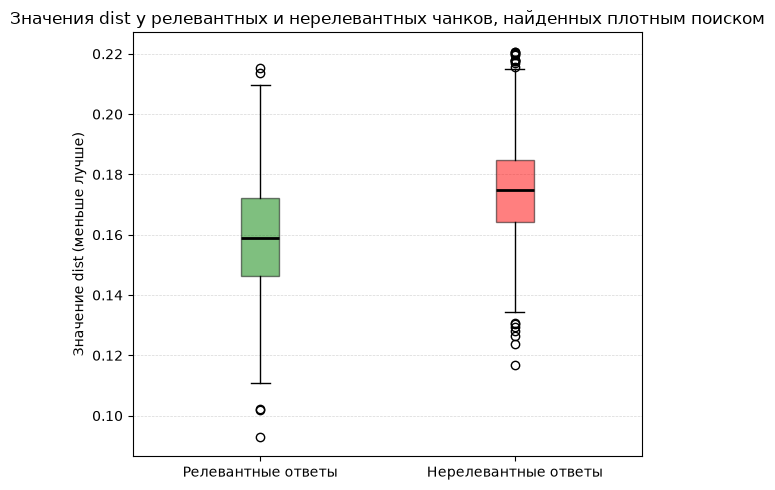

In [36]:
plt.figure(figsize=(6, 5))

# patch_artist=True позволяет раскрасить ящики
# medianprops настраивает линию медианы внутри ящика
box = plt.boxplot([relevant_dist_scores, irrelevant_dist_scores],
                  tick_labels=['Релевантные ответы', 'Нерелевантные ответы'],
                  patch_artist=True,
                  medianprops={'color': 'black', 'linewidth': 2})

# Раскрашиваем ящики в разные цвета для наглядности
colors = ['green', 'red']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)  # Делаем цвета приятнее с помощью прозрачности

plt.title('Значения dist у релевантных и нерелевантных чанков, найденных плотным поиском')
plt.ylabel('Значение dist (меньше лучше)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


По графику видно, что есть много выбросов, где нерелевантные ответы получили близкую оценку dist. Думаю, что это будет устранено позже с помощью реранкера. Если взять порог отсечения `dist<=0.16`, тогда мы забираем больше половины релевантных ответов и отсекаем нижнюю квартиль нерелевантных ответов, что очень хорошо. Думаю, что это вполне рабочее значение.

### Проверка фильтрации по метаданным

Создаём класс-обёртку для возможности фильтрации по метаданным

In [37]:
class MetadataFilteredDenseRetriever(BaseRetriever):
    """
    Класс-обёртка над DenseRetriever, который добавляет возможность
    фильтрации результатов по метаданным.
    """
    def __init__(self, retriever: DenseRetriever, metadata_filter: Dict[str, Any]):
        """
        :param retriever: Экземпляр DenseRetriever, который мы оборачиваем.
        :param metadata_filter: Словарь с правилами фильтрации (например, {"user_id": 123, "type": "doc"}).
        """
        self.base_retriever = retriever
        self.metadata_filter = metadata_filter

    def retrieve(self, query: str, top_k: int) -> List[RetrievedResult]:
        query_text = normalize_text(query)
        docs_with_scores = self.base_retriever.vector_store.similarity_search_with_score(
            query_text,
            k=top_k,
            filter=self.metadata_filter
        )
        results = []
        for rank, (doc, score) in enumerate(docs_with_scores, start=1):
            results.append(RetrievedResult(doc=doc, score=score, rank=rank))

        return results

In [38]:
test_query_text = "что делать если забыл пароль"

filtered_retriever = MetadataFilteredDenseRetriever(retriever=dense_retriever, metadata_filter={"category": "Аккаунт и профили"})

# Запрос с фильтром по категории "Аккаунт и профили"
print("Запрос с фильтром по категории Аккаунт и профили")
for res in filtered_retriever.retrieve(query=test_query_text, top_k=10):
    chunk = res.doc
    doc_id = chunk.metadata.get("doc_id")
    title = chunk.metadata.get("title")
    category = chunk.metadata.get("category")
    print(f"\tDoc: id={doc_id}, \tcategory={category}, \ttitle={title}")


# Запрос без фильтра
print("Запрос без фильтра")
for res in dense_retriever.retrieve(query=test_query_text, top_k=10):
    chunk = res.doc
    doc_id = chunk.metadata.get("doc_id")
    title = chunk.metadata.get("title")
    category = chunk.metadata.get("category")
    print(f"\tDoc: id={doc_id}, \tcategory={category}, \ttitle={title}")


Запрос с фильтром по категории Аккаунт и профили
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=55, 	category=Аккаунт и профили, 	title=Восстановление пароля
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=55, 	category=Аккаунт и профили, 	title=Восстановление пароля
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=41, 	category=Аккаунт и профили, 	title=Уведомления о входе в аккаунт
Запрос без фильтра
	Doc: id=173, 	category=Аккаунт и профили, 	title=Что делать при подозрении на взлом
	Doc: id=173, 	category=Аккаунт

Видим, что даже без фильтра, плотный поиск довольно хорошо находит нужную категорию, без её явного указания, но запрос без фильтров (второй) привёл к появлению выбросов из других категорий.

### baseline-метрики на запросах с ответом в базе

_Для подсчёта baseline метрик можно воспользоваться классами и функциями, которые мы использовали для выбора стратегии чанкинга._

In [39]:
dense_retriever = DenseRetriever(vector_store=main_vector_store)
dense_retriever_experiment_engine = RAGExperimentEngine(dense_retriever, [query for query in queries if query["kind"] != "gap"])
for k in (1, 3, 5, 10, 20):
    raw_m_rec, raw_t_rec, time_rec = dense_retriever_experiment_engine.run(top_k=k)
    report_rec = RAGAnalyzer.analyze(top_k=k, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
    report_rec.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=1) [метрики по разделам]
 Средняя Точность (Precision): 0.5714
 Средняя Полнота (Recall):    0.4821
 Средний MRR:                 0.5714
 Общее время поиска:          0.57 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.4286
 Средняя дельта Recall:     0.3482

 лучшие запросы (Max Recall):
  [разделы: 1/1, recall: 1.00/1.00] что означает ошибка P-102
  [разделы: 1/1, recall: 1.00/1.00] обязателен ли HDCP 2.2 для просмотра в 4K
  [разделы: 1/1, recall: 1.00/1.00] как подключить саундбар по HDMI ARC
-----------------------------------------------------------------

 худшие запросы (Min Recall):
  [разделы: 0/2, recall: 0.00/0.50] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
  [разделы: 0/2, recall: 0.00/0.50] хочу смотреть в 4K — какой нужен тариф и какая скорость интернета
  [разделы: 0/2, recall: 0.00/0.50] сменил пароль — нужно ли что-то делать с устройствами, где я уже вош

Запишем результаты:
| Значение K | Средний Precision | Средний Delta Precision | Средний Recall | Средний Delta Recall | Средний MRR |
|:----------:|:-----------------:|:-----------------------:|:--------------:|:--------------------:|:-----------:|
|     1      |      0.5714       |         0.4286         |    0.4821    |        0.3482        |   0.5714   |
|     3      |      0.4167       |         0.5833         |     0.6518     |        0.3482       |   0.6518    |
|     5      |      0.3571       |         0.6429         |     0.7321     |         0.2679       |   0.6714    |
|     10     |      0.2804       |         0.7196          |    0.7768     |        0.2232       |   0.6744    |
|     20     |      0.1804       |         0.8196         |     0.9018    |        0.0982        |   0.6798    |

# Диагностика и улучшение retrieval

Ожидаемо `recall` растет при увеличении `top-k`, а `precision` падает. Абсолютные значения `precision` ничего не значат, ведь зазор до потолка по `precision` очень сильно снизился при `top-k=20`. Видим, что `recall` прилично растёт. По среднему `MRR` видим, что в среднем релевантные запросы попадают в среднем на первую или вторую позицию. `MRR` сможем поднять через реранкер, а `recall` через гибридный поиск или оптимизацию запроса.

Рассмотрим запросы с низкими метриками recall на `top-k=30`

In [40]:
raw_m_rec, raw_t_rec, time_rec = dense_retriever_experiment_engine.run(top_k=30)
report_rec = RAGAnalyzer.analyze(top_k=30, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
report_rec.print_summary()


 ОБЩИЙ ОТЧЕТ (N=56, top-k=30) [метрики по разделам]
 Средняя Точность (Precision): 0.1333
 Средняя Полнота (Recall):    0.9107
 Средний MRR:                 0.6798
 Общее время поиска:          0.48 сек
-----------------------------------------------------------------
 Средняя дельта Precision:  0.8667
 Средняя дельта Recall:     0.0893

 лучшие запросы (Max Recall):
  [разделы: 2/2, recall: 1.00/1.00] хочу годовую подписку — в чём выгода и как её потом отменить
  [разделы: 2/2, recall: 1.00/1.00] на новом телевизоре пишет, что достигнут лимит устройств — как отвязать старые и войти
  [разделы: 2/2, recall: 1.00/1.00] кажется, кто-то чужой заходит в мой аккаунт
-----------------------------------------------------------------

 худшие запросы (Min Recall):
  [разделы: 0/2, recall: 0.00/1.00] заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
  [разделы: 0/1, recall: 0.00/1.00] в приложении всё включено, а на телефон ничего не приходит
  [разделы: 0/1, recal

In [41]:
bad_query1 = next((q for q in queries if q["query"].startswith("заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код")), None)
bad_query2 = next((q for q in queries if q["query"].startswith("в приложении всё включено, а на телефон ничего не приходит")), None)
bad_query3 = next((q for q in queries if q["query"].startswith("хочу убрать из ленты фильмы, которые уже смотрел")), None)

Посмотрим худшие запросы детально

In [42]:
dense_retriever_problem_queries_engine = RAGExperimentEngine(dense_retriever, [bad_query1, bad_query2, bad_query3])
raw_m_rec, raw_t_rec, time_rec = dense_retriever_problem_queries_engine.run(top_k=30)
report_rec = RAGAnalyzer.analyze(top_k=30, raw_metrics=raw_m_rec, raw_traces=raw_t_rec, total_time=time_rec)
report_rec.print_detailed_traces()


 запрос: заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
Ранг  | Релевантный | Score    | Раздел | Текст чанка
--------------------------------------------------------------------------------------------------------------
1     | [-]         | 0.1643   | 116    | # Подписка и оплата ## Часто задаваемые вопросы об оплате Здесь собраны короткие ответы на вопросы, …
2     | [-]         | 0.1648   | 154    | # Подписка и оплата ## Что делать, если оплата не прошла Читайте также Как оформить подписку Настрой…
3     | [-]         | 0.1692   | 173    | # Аккаунт и профили ## Что делать при подозрении на взлом Читайте также Как оформить подписку Настро…
4     | [-]         | 0.1693   | 71     | # Ошибки воспроизведения ## Статья обновляется Статья обновляется Раздел временно недоступен Статья …
5     | [-]         | 0.1700   | 110    | # Устройства и качество ## Что нужно для просмотра в 4K HDR Как оформить подписку Настройка телевизо…
6     | [-]         | 0.17

Диагноз по 3 худшим вопросам:
1. `заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код` - здесь явно видно два вопроса пользователя в одном. Это размывает вектор плотного поиска.
2. `в приложении всё включено, а на телефон ничего не приходит` - здесь пользователь описывает сценарий. Намерение пользователя не понять.
3. `хочу убрать из ленты фильмы, которые уже смотрел` - пользователь пишет своё намерение живым языком

Мой вердикт:

1. **реранкер cross-encoder**: рассмотреть для поднятия релевантных чанков в выдаче
2. **query expansion**: не поможет, так как проблемные запросы не используют специфических терминов. Скорее всего только снизит recall.
3. **HyDE**: рассмотреть для поднятия recall, так как проблемные запросы написаны живым языком и вообще зачастую имеют непонятное намерение пользователя.
4. **гибридный поиск с BM25**: не вижу необходимости, поскольку эмбеддер достаточно хороший и запросы, содержащие конкретые "якоря" вроде кодов ошибок или названия технологий, и так оказываются в топе выдачи. Хотя, это конечно может стать проблемой в будущем, когда появятся новые коды ошибок. В таком случае плотный поиск будет "склеивать" семантически их.
5. **слияние результатов через RRF**: рассмотреть для применения вместе с HyDE


## Cross encoder и reranker

Сначала попытаемся поднять средний MRR. Вводим Reranking (Cross-Encoder). Cross encoder добавляется в самый конец нашей цепочки декораторов.

In [43]:
from sentence_transformers import CrossEncoder

cross_encoder_reranker_model = CrossEncoder("BAAI/bge-reranker-v2-m3", device="mps")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

In [44]:
class RerankedRetriever(BaseRetriever):
    def __init__(
        self,
        base_retriever: BaseRetriever,
        cross_encoder: CrossEncoder,
        rerank_k: int = 30
    ):
        """
        :param base_retriever: Базовый retriever
        :param cross_encoder: Уже инициализированный объект CrossEncoder
        :param rerank_k: Сколько документов запросить у базового retriever для переранжирования
        """
        self.base_retriever = base_retriever
        self.cross_encoder = cross_encoder
        self.rerank_k = rerank_k

    def retrieve(self, query: str, top_k: int = 5) -> List[RetrievedResult]:
        query = normalize_text(query)
        initial_results = self.base_retriever.retrieve(query, top_k=self.rerank_k) # Получаем широкий набор документов (Bi-Encoder)

        if not initial_results:
            return []

        # Подготовка пар (query, text)
        pairs = [[query, res.doc.page_content] for res in initial_results]

        # Вычисление скоров
        rerank_scores = self.cross_encoder.predict(pairs, batch_size=8, show_progress_bar=False)

        # 4. Сборка результатов
        reranked_results = []
        for i, score in enumerate(rerank_scores):
            reranked_results.append(RetrievedResult(
                doc=initial_results[i].doc,
                score=float(score),
                rank=i + 1
            ))

        # 5. Сортировка и обрезка
        reranked_results.sort(key=lambda x: x.score, reverse=True)
        return reranked_results[:top_k]

In [45]:
# 1. Настройка ретриверов
dense_retriever = DenseRetriever(vector_store=main_vector_store)

rerank_retriever = RerankedRetriever(
    base_retriever=dense_retriever,
    cross_encoder=cross_encoder_reranker_model,
    rerank_k=30  # мы даем реранкеру 30 кандидатов, чтобы он вытащил лучших
)

TOP_K = 5 # Фиксируем значение для эксперимента

# 2. Запуск эксперимента для Baseline (Bi-Encoder)
# Мы сравниваем только то, что попадает в финальный топ-5
engine_baseline = RAGExperimentEngine(
    dense_retriever,
    [q for q in queries if q["kind"] != "gap"]
)
raw_m_base, raw_t_base, time_base = engine_baseline.run(top_k=TOP_K)
report_base = RAGAnalyzer.analyze(TOP_K, raw_m_base, raw_t_base, time_base)

# 3. Запуск эксперимента для Reranker
engine_rerank = RAGExperimentEngine(
    rerank_retriever,
    [q for q in queries if q["kind"] != "gap"]
)
raw_m_rerank, raw_t_rerank, time_rerank = engine_rerank.run(top_k=TOP_K)
report_rerank = RAGAnalyzer.analyze(TOP_K, raw_m_rerank, raw_t_rerank, time_rerank)

# 4. Сравнительная таблица (визуализация)
import pandas as pd

comparison_data = {
    "Metric": [f"Avg Precision@{TOP_K}", f"Avg Recall@{TOP_K}", "Avg MRR"],
    "Baseline (Bi-Encoder)": [
        f"{report_base.summary.avg_precision:.4f}",
        f"{report_base.summary.avg_recall:.4f}",
        f"{report_base.summary.avg_mrr:.4f}"
    ],
    "Reranker (Bi + Cross)": [
        f"{report_rerank.summary.avg_precision:.4f}",
        f"{report_rerank.summary.avg_recall:.4f}",
        f"{report_rerank.summary.avg_mrr:.4f}"
    ]
}

print(pd.DataFrame(comparison_data))

            Metric Baseline (Bi-Encoder) Reranker (Bi + Cross)
0  Avg Precision@5                0.3571                0.4429
1     Avg Recall@5                0.7321                0.8482
2          Avg MRR                0.6714                0.7812


Результат:

Видим явное улучшение по всем параметрам: avg precision@5 вырос с `0.3571` до `0.4429`. Это означает то, что в топ-5 перемещается больше релевантных результатов. Об этом говорит и возросший средний MRR с `0.6714` до `0.7812`. Возросший с `0.7321` до `0.8482` recall говорит о том, что ранжирование 30 потенциальных кандидатов даёт больше нужных результатов в топ-5, чем просто плотный поиск и извлечение 5. Это было ожидаемо.

## HyDE и слияние результатов через RRF

**Пробуем улучшить выдачу, внедрив следующий пайплайн**

**ЭТАП 1**: Расширение контекста (Expansion)
Цель: Сделать запрос более "богатым" для векторного поиска.

Запрос передается в HyDE (LLM).
HyDE генерирует "Гипотетический ответ" (короткий текст, который мог бы быть ответом на вопрос).

**ЭТАП 2**: Параллельный поиск (Multi-Path Retrieval)

Цель: Максимально широко "закинуть сети", чтобы не пропустить ни одного релевантного чанка.

Путь А (Прямой):

* Оригинальный запрос
* Dense Retriever
* **Список чанков 1**

Путь Б (Смысловой):

* Гипотетический ответ
* Dense Retriever
* **Список чанков 2**

**ЭТАП 3**: Слияние результатов (Fusion)

Цель: Объединить результаты двух путей в один качественный список.


**RRF объединяет списки:**

*   Если чанк найден в обоих списках, он получает высокий приоритет.
*   Если чанк найден только в одном, он получает средний приоритет.
*   Дубликаты удаляются.

**Результат: Один отсортированный список "кандидатов" (например, топ-30).**

**ЭТАП 4**: Финальное уточнение (Refinement)

**Цель**: Исключить шум и поставить самые точные чанки на 1-е места.

Список кандидатов отправляем в Cross-Encoder (Reranker), который отбирает топ-5

Для генерации здесь и далее будем использовать модель `google/gemma-4-e2b`, запущенную локально через LM Studio и доступную по API

In [46]:
import time
import logging
from openai import OpenAI, RateLimitError, APITimeoutError, APIConnectionError, APIStatusError
from tenacity import (
    retry,
    stop_after_attempt,
    wait_exponential,
    retry_if_exception_type,
    before_sleep_log
)

# Настройка логирования, чтобы видеть в консоли, когда происходит retry
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class RobustLLMClient:
    """
    Надежный клиент для общения с LLM.
    Реализует экспоненциальный backoff с jitter и обработку ошибок API.
    """
    def __init__(self, model: str, base_url: str, api_key: str = "not-needed", extra_body: dict = None):
        self.client = OpenAI(base_url=base_url, api_key=api_key)
        self.model = model
        self.extra_body = extra_body or {}

    # Настройка стратегии повторных попыток:
    # - Ждать экспоненциально: 2s, 4s, 8s...
    # - Добавляем jitter (случайное отклонение), чтобы не "долбить" сервер одновременно с другими
    # - Пытаемся не более 5 раз
    @retry(
        retry=retry_if_exception_type((RateLimitError, APITimeoutError, APIConnectionError, APIStatusError)),
        wait=wait_exponential(multiplier=1, min=2, max=10), # Добавит jitter автоматически
        stop=stop_after_attempt(5),
        before_sleep=before_sleep_log(logger, logging.WARNING)
    )
    def chat(self, messages: list, max_tokens: int = 160, temperature: float = 0.0):
        """
        Метод для выполнения запроса с автоматическими повторами при сетевых ошибках
        или превышении лимитов (429, 5xx).
        """
        return self.client.chat.completions.create(
            model=self.model,
            messages=messages,
            temperature=temperature,
            max_tokens=max_tokens,
            extra_body=self.extra_body,
            reasoning_effort="none",
            seed=1
        )

In [47]:
hyde_llm_client = RobustLLMClient(
    model="google/gemma-4-e2b",
    base_url="http://localhost:8080/v1",
    extra_body={"chat_template_kwargs": {"enable_thinking": False}}
)

In [48]:
class HyDERetriever(BaseRetriever):
    """
    Декоратор-обертка для ретривера, реализующая стратегию Hypothetical Document Embeddings.
    Использует RobustLLMClient для надежной генерации гипотетического документа.
    """
    def __init__(
        self,
        base_retriever: BaseRetriever,
        llm_client: RobustLLMClient
    ):
        """
        :param base_retriever: Редактируемый ретривер (например, DenseRetriever)
        :param llm_client: Экземпляр RobustLLMClient
        """
        self.base_retriever = base_retriever
        self.llm_client = llm_client

    def retrieve(self, query: str, top_k: int = 10) -> List[RetrievedResult]:

        query = normalize_text(query)

        # 1. Подготавливаем сообщение для LLM
        messages = [
        {"role": "system", "content": "Ты пишешь короткие ответы из базы знаний онлайн-кинотеатра."},
        {"role": "user", "content": f"Напиши короткий (1-2 предложения) фрагмент-ответ из базы знаний на вопрос клиента официальным языком. Только "
         f"текст ответа.\n\nВопрос: {query}"}
        ]

        response = self.llm_client.chat(
                messages=messages,
                max_tokens=150,
                temperature=0,
            )
        hypothetical_doc = response.choices[0].message.content

        # 3. Используем сгенерированный текст для поиска в векторном хранилище
        return self.base_retriever.retrieve(hypothetical_doc, top_k=top_k)

In [49]:
from collections import defaultdict


class ExperimentalPipelineRetriever(BaseRetriever):
    """
    Экспериментальный RAG-пайплайн [Reranker (RRF(Bi + HyDE) + Cross)]
    """
    def __init__(
        self,
        retrievers: List[BaseRetriever],
        cross_encoder: CrossEncoder,
        search_k: int = 30
    ) -> None:
        self.retrievers = retrievers
        self.cross_encoder = cross_encoder
        self.search_k = search_k

    def _rerank(self, candidates: List[RetrievedResult], query: str, top_k: int = 5) -> List[RetrievedResult]:
        """
        Принимает список уже найденных кандидатов и переранжирует их.
        """
        if not candidates:
            return []

        # Подготовка пар для Cross-Encoder
        pairs = [[query, res.doc.page_content] for res in candidates]

        # Вычисление скоров
        scores = self.cross_encoder.predict(pairs, batch_size=8, show_progress_bar=False)

        for i, score in enumerate(scores):
            candidates[i].score = float(score)

        # Сортировка по новому скору
        candidates.sort(key=lambda x: x.score, reverse=True)
        return candidates[:top_k]

    def _rrf(self, ranked_lists: List[List[RetrievedResult]], k: int = 60, top_k: int = 5) -> List[RetrievedResult]:
        """
        Reciprocal Rank Fusion: сливает несколько выдач по рангам.
        Ориентируется на уникальный chunk_id для корректного объединения.
        """
        scores = defaultdict(float)
        # Хранилище для объектов RetrievedResult, чтобы вернуть их в конце
        # Ключом будет уникальный chunk_id
        chunk_map = {}

        for lst in ranked_lists:
            for rank, res in enumerate(lst, start=1):
                # Получаем уникальный ID конкретного чанка из метаданных
                chunk_id = res.doc.metadata.get('chunk_id')

                if chunk_id is None:
                    # Если у чанка нет ID, мы не можем его корректно ранжировать через RRF
                    continue

                # Формула RRF: score = 1 / (k + rank)
                score = 1.0 / (k + rank)
                scores[chunk_id] += score

                # Сохраняем объект результата для этого чанка.
                # Если чанк встречается в разных списках, мы просто перезаписываем его,
                # так как нам важен сам объект для возврата, а вес (score) мы уже учли.
                chunk_map[chunk_id] = res

        # Сортируем ID чанков по накопленному баллу RRF (от большего к меньшему)
        sorted_chunk_ids = sorted(scores.items(), key=lambda x: -x[1])

        # Собираем итоговый список объектов RetrievedResult, ограниченный top_k
        final_results = []
        for chunk_id, score in sorted_chunk_ids[:top_k]:
            res = chunk_map[chunk_id]
            final_results.append(res)

        return final_results

    def retrieve(self, query: str, top_k: int = 5) -> List[RetrievedResult]:
        """
        Единая точка входа для запроса.
        """
        # 1. Параллельный поиск (Expansion)
        # Используем широкий search_k для полноты охвата перед слиянием
        retrieved_result_lists: List[List[RetrievedResult]] = []

        for retriever in self.retrievers:
            retrieved_result_lists.append(retriever.retrieve(query, top_k=self.search_k))

        # 2. Слияние (Fusion)
        # Объединяем результаты двух путей в один список кандидатов
        fused_candidates = self._rrf(retrieved_result_lists, top_k=self.search_k)

        # 3. Уточнение (Refinement)
        # Переранжируем объединенный список
        final_results = self._rerank(candidates=fused_candidates, query=query, top_k=top_k)

        # Обрезаем до финального top_k
        return final_results[:top_k]

Сравнение

In [50]:
TOP_K = 5 # Фиксируем значение для эксперимента
SEARCH_K = 30 # Фиксируем значение для эксперимента

# === Кандидат 1 Reranker (Bi + Cross) ===

# Reranker (Bi + Cross). Это ретривер, результат которого мы зафиксировали в прошлый раз
dense_retriever = DenseRetriever(vector_store=main_vector_store)

rerank_retriever = RerankedRetriever(
    base_retriever=dense_retriever,
    cross_encoder=cross_encoder_reranker_model,
    rerank_k=SEARCH_K  # мы даем реранкеру 30 кандидатов, чтобы он вытащил лучших
)

# Запуск эксперимента для [Reranker (Bi + Cross)]
engine_rerank = RAGExperimentEngine(
    rerank_retriever,
    [q for q in queries if q["kind"] != "gap"]
)
raw_m_rerank, raw_t_rerank, time_rerank = engine_rerank.run(top_k=TOP_K)
report_rerank = RAGAnalyzer.analyze(TOP_K, raw_m_rerank, raw_t_rerank, time_rerank)


# === Кандидат 2 [Reranker (RRF(Bi + HyDE) + Cross)] ===

hyde_retriever = HyDERetriever(base_retriever=dense_retriever, llm_client=hyde_llm_client)
exp_pipeline_retriever = ExperimentalPipelineRetriever(retrievers=[dense_retriever, hyde_retriever],
                                     cross_encoder=cross_encoder_reranker_model,
                                     search_k=SEARCH_K)

# 2. Запуск эксперимента для экспериментального пайплайна [Reranker (RRF(Bi + HyDE) + Cross)]
# Мы сравниваем только то, что попадает в финальный топ-5
engine_exp_pipeline = RAGExperimentEngine(
    exp_pipeline_retriever,
    [q for q in queries if q["kind"] != "gap"]
)
raw_m_exp_pipeline, raw_t_exp_pipeline, time_exp_pipeline = engine_exp_pipeline.run(top_k=TOP_K)
report_new_pipeline = RAGAnalyzer.analyze(TOP_K, raw_m_exp_pipeline, raw_t_exp_pipeline, time_exp_pipeline)

# 4. Сравнительная таблица (визуализация)
import pandas as pd

comparison_data = {
    "Metric": [f"Avg Precision@{TOP_K}", f"Avg Recall@{TOP_K}", "Avg MRR"],
    "[Reranker (Bi + Cross)]": [
        f"{report_rerank.summary.avg_precision:.4f}",
        f"{report_rerank.summary.avg_recall:.4f}",
        f"{report_rerank.summary.avg_mrr:.4f}"
    ],
    "Experimental pipeline[Reranker (RRF(Bi + HyDE) + Cross)]": [
        f"{report_new_pipeline.summary.avg_precision:.4f}",
        f"{report_new_pipeline.summary.avg_recall:.4f}",
        f"{report_new_pipeline.summary.avg_mrr:.4f}"
    ]
}

print(pd.DataFrame(comparison_data))

INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST http://localhost:8080/v1/chat/completions "HTTP/1.1 200 OK"
INFO:httpx

            Metric [Reranker (Bi + Cross)]  \
0  Avg Precision@5                  0.4429   
1     Avg Recall@5                  0.8482   
2          Avg MRR                  0.7812   

  Experimental pipeline[Reranker (RRF(Bi + HyDE) + Cross)]  
0                                             0.4500        
1                                             0.8661        
2                                             0.7878        


Запишем результаты:

|                                                                               Пайплайн | Средний Precision | Средний Recall | Средний MRR |
|---------------------------------------------------------------------------------------:|:-----------------:|:--------------:|:-----------:|
|                           **Bi-Encoder (top-k=30) и последующий cross-encoder reranker (top-k=5)** |      0.4429       |     0.8482      |   0.7812    |
| **cross encoder reranker (top-k=5) по RRF от (Bi-Encoder (top-k=30), HyDE(top-k=30))** |      0.4500       |     0.8661     |   0.7878    |

Показатели `avg precision`, `avg recall` и `avg mrr` немного выросли, однако это привело к значительному увеличению времени выполнения и добавлению лишней точки отказа. Внедрение экспериментального пайплайна не оправдывает себя.

Попробуем увеличить количество top-k кандидатов для реранкера до 50. Это быстрее чем вызов внешней LLM в HyDE.

In [51]:
TOP_K = 5 # Фиксируем значение для эксперимента
SEARCH_K = 50 # Фиксируем значение для эксперимента

# === Кандидат 1 Reranker (Bi + Cross) ===

# Reranker (Bi + Cross). Это ретривер, результат которого мы зафиксировали в прошлый раз
dense_retriever = DenseRetriever(vector_store=main_vector_store)

rerank_retriever = RerankedRetriever(
    base_retriever=dense_retriever,
    cross_encoder=cross_encoder_reranker_model,
    rerank_k=SEARCH_K  # мы даем реранкеру 30 кандидатов, чтобы он вытащил лучших
)

# Запуск эксперимента для [Reranker (Bi + Cross)]
engine_rerank = RAGExperimentEngine(
    rerank_retriever,
    [q for q in queries if q["kind"] != "gap"]
)
raw_m_rerank, raw_t_rerank, time_rerank = engine_rerank.run(top_k=TOP_K)
report_rerank = RAGAnalyzer.analyze(TOP_K, raw_m_rerank, raw_t_rerank, time_rerank)

# 4. Сравнительная таблица (визуализация)
import pandas as pd

comparison_data = {
    "Metric": [f"Avg Precision@{TOP_K}", f"Avg Recall@{TOP_K}", "Avg MRR"],
    "[Reranker (Bi + Cross)]": [
        f"{report_rerank.summary.avg_precision:.4f}",
        f"{report_rerank.summary.avg_recall:.4f}",
        f"{report_rerank.summary.avg_mrr:.4f}"
    ]
}

print(pd.DataFrame(comparison_data))

            Metric [Reranker (Bi + Cross)]
0  Avg Precision@5                  0.4607
1     Avg Recall@5                  0.9196
2          Avg MRR                  0.8161


Результат значительно улучшился БЕЗ необходимости добавлять лишнюю интеграцию с LLM в систему для HyDE. Достигается целевое значение по ТЗ `recall@5 >= 0,85 для итоговой версии поиска — по запросам, ответ на которые есть в базе;`. Также значительно вырос средний MRR c `0.7812` до `0.8161`.

## Решение и выводы

Считаю разумным остановиться на связке bi-encoder + cross-encoder с последующим реранкингом. Увеличить число кандидатов для реранкера до 50. Введение в эту цепочку HyDE только добавило задержки по времени и ещё одну точку отказа (обращения к API по HTTP), слабо при этом улучшив итоговый результат.

# Этап 5. Генерация ответов

Для прототипа будем строить LangChain Pipeline, поскольку у нас уже подготовлены документы в формате LangChain и фреймворк полностью покрывает наши стандартные потребности.
Для генерации будем использовать всё ту же модель `google/gemma-4-e2b`. На прошлом шаге было решено использовать плотный поиск с реранкером из **50** кандидтов со сжатием до 5.

In [52]:
import logging
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

LLM_SERVER_BASE_URL = "http://localhost:8080/v1"
NO_THINK_BODY = {
        "chat_template_kwargs": {
            "enable_thinking": False,
        },
        "reasoning_effort": "none",
        "reasoning": {"enabled": False}
    }

# Настройка LLM
llm = ChatOpenAI(
    base_url=LLM_SERVER_BASE_URL,
    api_key="not-needed",
    model="google/gemma-4-e2b",
    temperature=0.0,
    max_tokens=1024,
    seed=1,
    extra_body=NO_THINK_BODY
)
logging.getLogger("httpx").setLevel(logging.WARNING)

# Промпт для ассистента
prompt = ChatPromptTemplate.from_messages([
    ("system",
     "Ты — ассистент поддержки. Отвечай ТОЛЬКО по приведённым фрагментам "
     "базы знаний. Если ответа в них нет, ответь: «В базе знаний ответа "
     "нет». Отвечай кратко, одним-двумя предложениями."),
    ("human", "Фрагменты базы знаний:\n{context}\n\nВопрос: {question}"),
])

dense_retriever = DenseRetriever(vector_store=main_vector_store)

rerank_retriever = RerankedRetriever(
    base_retriever=dense_retriever,
    cross_encoder=cross_encoder_reranker_model,
    rerank_k=50  # мы даем реранкеру 50 кандидатов, чтобы он вытащил лучших
)

def generate_context_from_chunks(input_chunks: list[Document]) -> str:
    if not input_chunks:
        return ""
    # Применяем анти-Lost-in-the-Middle сортировку
    reordered_chunks = [None] * len(input_chunks)
    left, right = 0, len(input_chunks) - 1
    for i, doc in enumerate(input_chunks):
        if i % 2 == 0:
            reordered_chunks[left] = doc
            left += 1
        else:
            reordered_chunks[right] = doc
            right -= 1

    # Форматируем финальный контекст для промпта
    return "\n".join(f"[{n}] {chunk.page_content}" for n, chunk in enumerate(reordered_chunks, 1))


def get_context_from_rerank_retriever(query: str) -> str:

    reranked_results = rerank_retriever.retrieve(query, top_k=5)

    if not reranked_results:
        return ""

    # Извлекаем объекты документов
    chunks = [res.doc for res in reranked_results]

    return generate_context_from_chunks(chunks)

In [53]:
from typing import Union, List, Callable
from langchain_core.runnables import RunnablePassthrough, RunnableLambda
from langchain_core.output_parsers import StrOutputParser
from langchain_core.documents import Document

from langchain_core.runnables import RunnablePassthrough, RunnableLambda
from langchain_core.output_parsers import StrOutputParser

# 1. Рабочая цепочка (Продакшн)
def create_production_rag_chain(llm, prompt, retriever_func):
    """
    Создает RAG-цепочку для продакшена.
    retriever_func принимает строку (вопрос) и возвращает строку (отформатированный контекст).
    """
    return (
        {
            # retriever_func получает вопрос напрямую как строку
            "context": RunnableLambda(retriever_func),
            "question": RunnablePassthrough()
        }
        | prompt
        | llm
        | StrOutputParser()
    )


# 2. Тестовая цепочка (Золотой контекст)
def create_test_rag_chain(llm, prompt, golden_documents, context_formatter_func):
    """
    Создает тестовую RAG-цепочку.
    Игнорирует поиск, берет готовые golden_documents, форматирует их через
    функцию context_formatter_func и подставляет в промпт.
    """
    # Заранее готовим строку контекста из золотых документов,
    # прогоняя их через вашу функцию сортировки generate_context_from_chunks
    formatted_context = context_formatter_func(golden_documents)

    return (
        {
            # Цепочка при каждом вызове будет просто отдавать уже готовый текст
            "context": RunnableLambda(lambda x: formatted_context),
            "question": RunnablePassthrough()
        }
        | prompt
        | llm
        | StrOutputParser()
    )

In [54]:
rag_chain = create_production_rag_chain(
    llm=llm,
    prompt=prompt,
    retriever_func=get_context_from_rerank_retriever
)

Проверим работу пайплайна на нескольких запросах

In [55]:
for q in queries[0:3]:
    text = normalize_text(q["query"])
    print("Вопрос: " + text)
    answer = rag_chain.invoke(text)
    print("Ответ: " + answer)
    print("\n")

Вопрос: что означает ошибка P-102
Ответ: Ошибка P-102 появляется, когда число одновременных просмотров на аккаунте превышает лимит тарифа, и это может прервать просмотр.


Вопрос: какая версия webOS или Tizen нужна для приложения на телевизоре
Ответ: Для работы приложения на телевизорах Smart TV требуются версии Samsung Tizen (модели с 2018 года) или LG webOS 4.0 и новее.


Вопрос: обязателен ли HDCP 2.2 для просмотра в 4K
Ответ: Для просмотра в 4K HDR необходимо проверить цепочку устройств, включая поддержку 4K и HDR10, а также защиту HDCP 2.2 всеми устройствами в цепочке.




In [56]:
test_gap_query = next(q for q in queries if q["kind"] == "gap")
test_query_text = normalize_text(test_gap_query["query"])
print("Вопрос: " + test_query_text)
test_query_answer = rag_chain.invoke(test_query_text)
print("Ответ: " + test_query_answer)

Вопрос: есть ли подарочные сертификаты
Ответ: В базе знаний ответа нет.


# Этап 6. Оценка качества и финальная диагностика

Для оценки качества воспользуемся кусками кода из уроков. В качестве модели судьи будем использовать `qwen2.5-3b-instruct-mlx` чтобы минимизировать judge bias

In [57]:
JUDGE_LLM = "qwen2.5-3b-instruct-mlx"
JUDGE_SEED = 1
judge_llm_client = OpenAI(
    base_url=LLM_SERVER_BASE_URL,
    api_key="not-needed",
)

JUDGE_SYSTEM = (
    "Ты — строгий эксперт по оценке справочных ответов. Оценивай "
    "беспристрастно, длина ответа не является достоинством. "
    "Отвечай только JSON-объектом."
)

FAITH_PROMPT = """Оцени ВЕРНОСТЬ КОНТЕКСТУ (faithfulness):
следует ли каждое утверждение ответа из фрагментов.
Соответствие вопросу не оценивай — только происхождение фактов.

Шкала:
5 — все утверждения следуют из фрагментов;
4 — добавлено только безобидное обобщение;
3 — добавлена неподтверждённая деталь;
2 — часть утверждений выдумана или противоречит фрагментам;
1 — ключевые факты отсутствуют во фрагментах или искажены.
Ответ «В базе знаний ответа нет» ничего не утверждает и получает 5.

Фрагменты:
{context}

Ответ: {answer}

Верни JSON с полями reason и score."""

REL_PROMPT = """Оцени РЕЛЕВАНТНОСТЬ (answer relevance):
отвечает ли ответ на заданный вопрос по существу.
Правдивость не проверяй — только соответствие вопросу.

Шкала:
5 — прямой и полный ответ;
4 — ответ по существу с небольшими отступлениями;
3 — закрыта только часть вопроса;
2 — текст на нужную тему, но ответа нет;
1 — другая тема или отказ отвечать.

Вопрос: {question}

Ответ: {answer}

Верни JSON с полями reason и score."""

GOLD_ANSWER_ADHERENCE_PROMPT = """Оцени СООТВЕТСТВИЕ ЭТАЛОННОМУ ОТВЕТУ:
насколько предложенный ответ совпадает по смыслу и фактам с эталонным ответом.
Стиль и формулировки могут отличаться, главное — сохранение сути, фактов и логики.

Шкала:
5 — идеальное совпадение: все ключевые факты и суть переданы верно, противоречий нет;
4 — хорошее совпадение: суть передана, но упущены мелкие детали или добавлены незначительные детали, которых не было в эталоне;
3 — частичное совпадение: передана лишь часть важных фактов, либо ответ слишком обобщенный;
2 — слабое совпадение: упомянута общая тема, но ключевые факты изменены или искажены;
1 — полное несоответствие: ответ содержит факты, противоречащие эталону, либо это совсем другая информация.

Эталонный ответ: {gold_answer}

Ответ для проверки: {answer}

Верни JSON с полями reason и score."""

CORRECTNESS_PROMPT = """Ты — строгий эксперт. Сравни ОТВЕТ с ЭТАЛОННЫМ ФАКТОМ. Верни 1, если ответ
передаёт эталонный факт (формулировка может отличаться), и 0, если ответ противоречит эталону, неполон или отказывается отвечать.

ВОПРОС: {question}

ЭТАЛОННЫЙ ФАКТ: {gold_answer}

ОТВЕТ: {answer}

Верни результат своей оценки в итоговом JSON в поле result"""

JUDGE_RESPONSE_FORMAT = {
    "type": "json_schema",
    "json_schema": {
        "name": "judge_response_format",
        "strict": True,
        "schema": {
            "type": "object",
            "properties": {
                "reason": {"type": "string", "maxLength": 240},
                "score": {
                    "type": "integer",
                    "minimum": 1,
                    "maximum": 5,
                },
            },
            "required": ["reason", "score"],
            "additionalProperties": False,
        }
    }
}

JUDGE_CORRECTNESS_FORMAT = {
    "type": "json_schema",
    "json_schema": {
        "name": "judge_response_correctness_format",
        "strict": True,
        "schema": {
            "type": "object",
            "properties": {
                "result": {
                    "type": "integer",
                    "minimum": 0,
                    "maximum": 1,
                }
            },
            "required": ["result"],
            "additionalProperties": False,
        }
    }
}


def judge(prompt):
    """Возвращает оценку 1–5 и обоснование LLM-судьи."""
    response = judge_llm_client.chat.completions.create(
        model=JUDGE_LLM,
        messages=[
            {"role": "system", "content": JUDGE_SYSTEM},
            {"role": "user", "content": prompt},
        ],
        temperature=0.0,
        max_tokens=200,
        reasoning_effort="none",
        response_format=JUDGE_RESPONSE_FORMAT,
        extra_body=NO_THINK_BODY,
    )
    value = json.loads(response.choices[0].message.content)
    score = value.get("score")
    reason = value.get("reason")
    if type(score) is not int or not 1 <= score <= 5:
        raise ValueError(f"Некорректная оценка судьи: {score!r}")
    if not isinstance(reason, str) or not reason.strip():
        raise ValueError("Судья не вернул обоснование")
    return score, reason.strip()

def judge_faithfulness(context, answer):
    """Оценивает верность ответа контексту."""
    prompt = FAITH_PROMPT.format(context=context, answer=answer)
    return judge(prompt)


def judge_relevance(question, answer):
    """Оценивает соответствие ответа вопросу."""
    prompt = REL_PROMPT.format(question=question, answer=answer)
    return judge(prompt)

def judge_gold_answer_adherence(answer, gold_answer):
    """Оценивает соответствие ответа эталонному ответу."""
    prompt = GOLD_ANSWER_ADHERENCE_PROMPT.format(gold_answer=gold_answer, answer=answer)
    return judge(prompt)

def judge_correctness(question, answer, gold_answer):
    """Оценивает соответствие ответа эталонному ответу."""
    prompt = CORRECTNESS_PROMPT.format(question=question, gold_answer=gold_answer, answer=answer)
    """Возвращает оценку 1–5 и обоснование LLM-судьи."""
    response = judge_llm_client.chat.completions.create(
        model=JUDGE_LLM,
        messages=[
            {"role": "system", "content": JUDGE_SYSTEM},
            {"role": "user", "content": prompt},
        ],
        temperature=0.0,
        max_tokens=200,
        reasoning_effort="none",
        response_format=JUDGE_CORRECTNESS_FORMAT,
        extra_body=NO_THINK_BODY,
    )
    value = json.loads(response.choices[0].message.content)
    result = value.get("result")
    if type(result) is not int or not 0 <= result <= 1:
        raise ValueError(f"Некорректная оценка судьи: {result!r}")
    return result

In [58]:
assessment_inputs = []

for i, q in enumerate(queries, start=1):
    print(f"Подготовка ответов для оценки {i} из {len(queries)}")
    query_text = normalize_text(q["query"])
    chunks = rerank_retriever.retrieve(query_text, top_k=5) # Получаем чанки тем же методом, что и пайплайн
    query_retrieved_context = generate_context_from_chunks([chunk.doc for chunk in chunks])
    answer = rag_chain.invoke(query_text)

    assessment_inputs.append({
        "query_text": query_text,
        "query_retrieved_context": query_retrieved_context,
        "query_retrieved_doc_ids": [chunk.doc.metadata.get('doc_id') for chunk in chunks],
        "query_relevant_docs": q["relevant_docs"],
        "answer": answer,
        "gold_answer": q["gold"],
        "query_kind": q["kind"]
    })

Подготовка ответов для оценки 1 из 66
Подготовка ответов для оценки 2 из 66
Подготовка ответов для оценки 3 из 66
Подготовка ответов для оценки 4 из 66
Подготовка ответов для оценки 5 из 66
Подготовка ответов для оценки 6 из 66
Подготовка ответов для оценки 7 из 66
Подготовка ответов для оценки 8 из 66
Подготовка ответов для оценки 9 из 66
Подготовка ответов для оценки 10 из 66
Подготовка ответов для оценки 11 из 66
Подготовка ответов для оценки 12 из 66
Подготовка ответов для оценки 13 из 66
Подготовка ответов для оценки 14 из 66
Подготовка ответов для оценки 15 из 66
Подготовка ответов для оценки 16 из 66
Подготовка ответов для оценки 17 из 66
Подготовка ответов для оценки 18 из 66
Подготовка ответов для оценки 19 из 66
Подготовка ответов для оценки 20 из 66
Подготовка ответов для оценки 21 из 66
Подготовка ответов для оценки 22 из 66
Подготовка ответов для оценки 23 из 66
Подготовка ответов для оценки 24 из 66
Подготовка ответов для оценки 25 из 66
Подготовка ответов для оценки 26 и

In [59]:
def is_refusal(answer):
    """Проверяет наличие договорной фразы отказа."""
    normalized = " ".join(answer.casefold().split())
    return "В базе знаний ответа нет".casefold() in normalized

In [60]:
def evaluate_coverage(retrieved_doc_ids: list[int], relevant_doc_ids: list[int]) -> float:
    '''
    Функция для расчёта доли покрытия извлеченными чанками чанков всех релевантных документов
    :param retrieved_doc_ids: список идентификаторов извлеченных документов
    :param relevant_doc_ids: список идентификаторов релевантных документов
    '''
    if not relevant_doc_ids:
        return 1.0

    if not retrieved_doc_ids:
        return 0.0

    # Превращаем извлеченные документы в set для быстрого поиска (O(1))
    retrieved_set = set(retrieved_doc_ids)

    relevant_set = set(relevant_doc_ids)

    # Находим пересечение: сколько нужных документов мы реально извлекли
    intersection = retrieved_set.intersection(relevant_set)

    # Возвращаем долю покрытия
    return len(intersection) / len(relevant_set)

In [61]:
def diagnose(is_gap_question: bool, is_refusal: bool, coverage: float | None, faithfulness: float, relevance: float):
    """Связывает наблюдаемую проблему с компонентом пайплайна."""
    if is_gap_question:
        if is_refusal:
            return "пробел в данных, отказ уместен"
        return "пробел в данных + ошибка генерации"

    if not coverage:
        return ""

    if coverage < 1:
        if faithfulness < 4:
            return "неполный retrieval + галлюцинация генератора"
        if relevance < 3:
            return "неполный retrieval + нерелевантный ответ"
        return "неполный retrieval; метрики генерации не заметили ошибку"

    if faithfulness < 4:
        return "ошибка генерации: галлюцинация при полном контексте"
    if relevance < 3:
        return "ошибка генерации: нерелевантный ответ или ложный отказ"
    return "наблюдаемой проблемы нет"

In [62]:
def assess_response(input_data: dict[str, Any]) -> dict[str, Any]:
    faithfulness, f_reason = judge_faithfulness(context=input_data["query_retrieved_context"],
                                                answer=input_data["answer"])
    relevance, r_reason = judge_relevance(question=input_data["query_text"], answer=input_data["answer"])
    gold_adherence, g_reason = judge_gold_answer_adherence(gold_answer=input_data["gold_answer"], answer=input_data["answer"])

    is_gap = input_data["query_kind"] == "gap" or not input_data["query_relevant_docs"]

    retrieved_doc_coverage = 1.0
    if not is_gap:
        retrieved_doc_coverage = evaluate_coverage(retrieved_doc_ids=input_data["query_retrieved_doc_ids"],
                                                   relevant_doc_ids=input_data["query_relevant_docs"])

    refused = is_refusal(input_data["answer"])
    retrieval_failed = not is_gap and retrieved_doc_coverage < 1
    needs_review = faithfulness < 4 or relevance < 3 or retrieval_failed or is_gap

    correctness = 0
    if refused:
        if is_gap:
            correctness = 1
        else:
            correctness = 0
    else:
        correctness = judge_correctness(question=input_data["query_text"], answer=input_data["answer"], gold_answer=input_data["gold_answer"])

    return {
        "input_data": input_data,
        "faithfulness": faithfulness,
        "faithfulness_reason": f_reason,
        "relevance": relevance,
        "relevance_reason": r_reason,
        "correctness": correctness,
        "gold_adherence": gold_adherence,
        "gold_adherence_reason": g_reason,
        "coverage": retrieved_doc_coverage,
        "refusal": refused,
        "diagnose": diagnose(is_gap_question=is_gap,
                             is_refusal=refused,
                             coverage=retrieved_doc_coverage,
                             faithfulness=faithfulness,
                             relevance=relevance),
        "needs_review": needs_review
    }

In [63]:
assessment_results = []
for i, input_data in enumerate(assessment_inputs, start=1):
    print(f"Оценка судьи {i} из {len(assessment_inputs)}")
    assessment_result = assess_response(input_data=input_data)
    assessment_results.append(assessment_result)

Оценка судьи 1 из 66
Оценка судьи 2 из 66
Оценка судьи 3 из 66
Оценка судьи 4 из 66
Оценка судьи 5 из 66
Оценка судьи 6 из 66
Оценка судьи 7 из 66
Оценка судьи 8 из 66
Оценка судьи 9 из 66
Оценка судьи 10 из 66
Оценка судьи 11 из 66
Оценка судьи 12 из 66
Оценка судьи 13 из 66
Оценка судьи 14 из 66
Оценка судьи 15 из 66
Оценка судьи 16 из 66
Оценка судьи 17 из 66
Оценка судьи 18 из 66
Оценка судьи 19 из 66
Оценка судьи 20 из 66
Оценка судьи 21 из 66
Оценка судьи 22 из 66
Оценка судьи 23 из 66
Оценка судьи 24 из 66
Оценка судьи 25 из 66
Оценка судьи 26 из 66
Оценка судьи 27 из 66
Оценка судьи 28 из 66
Оценка судьи 29 из 66
Оценка судьи 30 из 66
Оценка судьи 31 из 66
Оценка судьи 32 из 66
Оценка судьи 33 из 66
Оценка судьи 34 из 66
Оценка судьи 35 из 66
Оценка судьи 36 из 66
Оценка судьи 37 из 66
Оценка судьи 38 из 66
Оценка судьи 39 из 66
Оценка судьи 40 из 66
Оценка судьи 41 из 66
Оценка судьи 42 из 66
Оценка судьи 43 из 66
Оценка судьи 44 из 66
Оценка судьи 45 из 66
Оценка судьи 46 из 

In [64]:
def display_rag_results(data_list, max_text_len=150):
    """
    Превращает список словарей в чистую и красивую таблицу для Jupyter.
    Удаляет технические детали и скрывает индекс.
    """
    if not data_list:
        print("Список данных пуст")
        return pd.DataFrame()

    # 1. Разворачиваем вложенный словарь input_data
    df = pd.json_normalize(data_list)

    # Убираем префикс input_data. для удобства
    df.columns = [c.replace('input_data.', '') for c in df.columns]

    # 2. Удаляем ненужные столбцы
    cols_to_drop = ['query_retrieved_context', 'query_retrieved_chunk_ids']
    df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

    # 3. Функция для обрезки длинного текста
    def truncate(text):
        text = str(text)
        return text[:max_text_len] + '...' if len(text) > max_text_len else text

    # 4. Настройка стилей
    # Определяем колонки, текст в которых нужно обрезать
    text_cols = ['query_text', 'answer', 'gold_answer', 'faithfulness_reason', 'relevance_reason']
    text_cols = [c for c in text_cols if c in df.columns]

    # Начинаем стилизацию
    styled_df = df.style.format({
        **{col: truncate for col in text_cols}
    })

    # Настройка выравнивания, отступов и границ
    styled_df = styled_df.set_properties(**{
        'text-align': 'left',
        'white-space': 'normal',
        'border': '1px solid #ddd',
        'padding': '8px'
    })

    # Убираем столбец с индексом
    styled_df = styled_df.hide(axis='index')

    return styled_df


In [65]:
def summarize_rag_results(results_list):
    """
    Подсчитывает агрегированные метрики по списку результатов RAG.

    Args:
        results_list (list of dict): Список словарей с результатами.

    Returns:
        pd.DataFrame: Таблица с итоговыми метриками.
    """
    if not results_list:
        return pd.DataFrame([{
            'mean_faith': 0, 'faith_lt4': 0, 'actionable_rel_lt3': 0,
            'hit': 0, 'full_coverage': 0, 'proper_refusals': 0, 'false_refusals': 0, 'mean_correctness': 0
        }])

    # 1. Разворачиваем вложенные структуры (input_data.xxx)
    df = pd.json_normalize(results_list)

    # Вспомогательные маски для упрощения логики
    # query_kind == 'gap' означает, что ответа в базе нет
    is_gap = df['input_data.query_kind'] == 'gap'
    # refusal == True означает, что модель совершила отказ
    is_refusal = df['refusal'] == True

    # Определяем "уместный отказ" (proper refusal)
    # Это когда ответа в базе НЕТ (gap) И модель вернула системную фразу отказа
    is_proper_refusal = is_gap & is_refusal

    # Определяем "ложный отказ" (false refusal)
    # Это когда ответ в базе ЕСТЬ (not gap) И модель всё равно отказалась
    is_false_refusal = (~is_gap) & is_refusal

    # Подсчет метрик
    metrics = {
        # Средний faithfulness, округлённый до сотых
        'Средний faithfulness': round(df['faithfulness'].mean(), 2),


        'Средний gold answer adherence': round(df['gold_adherence'].mean(), 2),

        'Средний correctness': round(df['correctness'].mean(), 2),

        # Количество ответов с faithfulness ниже порога 4
        'Количество ответов ниже порога 4 по faithfulness': int(len(df[df['faithfulness'] < 4])),

        # Отказы с relevance < 3, исключая уместные (proper refusals)
        'Отказы с relevance < 3, исключая уместные (proper refusals)': int(len(df[(df['relevance'] < 3) & (~is_proper_refusal)])),

        # Hit: есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка
        # (Проверяем длину списка в колонке query_relevant_docs)
        'есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка': int(len(df[(~is_gap) & (df['input_data.query_relevant_docs'].apply(lambda x: len(x) > 0 if isinstance(x, list) else False))])),

        # Full coverage: есть ответ в базе (not gap) И coverage == 1
        'full_coverage': int(len(df[(~is_gap) & (df['coverage'] == 1)])),

        # Сколько уместных отказов
        'Сколько уместных отказов': int(is_proper_refusal.sum()),

        # Сколько ложных отказов
        'Сколько ложных отказов': int(is_false_refusal.sum())
    }

    # Возвращаем красивую таблицу
    return pd.DataFrame([metrics])


Посмотрим на резюме по оценкам

In [66]:
summarize_rag_results(assessment_results)

,Средний faithfulness,Средний gold answer adherence,Средний correctness,Количество ответов ниже порога 4 по faithfulness,"Отказы с relevance < 3, исключая уместные (proper refusals)",есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка,full_coverage,Сколько уместных отказов,Сколько ложных отказов
0,2.02,2.56,0.39,61,35,56,48,6,3


По предварительной оценке у нас страдает `faithfulness`

Чтобы понять какие у нас проблемы есть с retrieval посмотрим на несколько запросов, требующих review и имеющих оценку `0` за `correctness` и `coverage < 1`

In [67]:
display_rag_results([a for a in assessment_results if a["needs_review"] is True and a["correctness"] == 0 and a["coverage"] < 1])

faithfulness,faithfulness_reason,relevance,relevance_reason,correctness,gold_adherence,gold_adherence_reason,coverage,refusal,diagnose,needs_review,query_text,query_retrieved_doc_ids,query_relevant_docs,answer,gold_answer,query_kind
1,"Ответ не содержит утверждений, которые могут быть подтверждены или опровергнуты на основе предоставленных фрагментов. Ответ не содержит ключевой инфор...",2,"Ответ не отвечает на вопрос по существу. Он указывает на невозможность найти информацию в базе знаний, но не предоставляет конкретных рекомендаций или...",0,2,Ответ не содержит информации о сроке действия загрузки и необходимости подключения к интернету для продления или скачивания заново. Ответ слишком обобщенный и не отвечает на ключевые факты вопроса.,0.000000,True,,True,скачанная серия перестала открываться без интернета,"[109, 144, 94, 98, 144]",[49],В базе знаний ответа нет.,истёк срок действия загрузки (30 дней); нужно подключиться к интернету для продления или скачать заново,semantic
2,"Ответ содержит утверждения, которые не подтверждаются ни одним из предоставленных фрагментов. Например, утверждение 'Пароль повторяется на другом сайт...",3,"Ответ частично отвечает на вопрос, но не прямым образом указывает на взлом аккаунта. Он упоминает возможные причины, но не прямо отвечает на подозрени...",0,1,Ответ не содержит ключевых фактов смены пароля и выхода на всех устройствах. Он также не описывает отвязку незнакомых устройств.,0.500000,False,неполный retrieval + галлюцинация генератора,True,"кажется, кто-то чужой заходит в мой аккаунт","[173, 173, 41, 41, 173]","[9, 173]","Если вы подозреваете взлом, это может быть связано с тем, что пароль повторяется на другом сайте или вход остался на чужом устройстве.","сменить пароль, нажать «Выйти на всех устройствах» и отвязать незнакомые устройства",semantic
1,Ответ не содержит утверждений или фактов из предоставленных фрагментов. Он только предложил тему для обсуждения.,2,"Ответ не отвечает на вопрос по существу. Он указывает, что в базе знаний нет информации о Стандарте и Максимуме, но не содержит полного или прямого от...",0,1,"Ответ не содержит информации о максимуме и его характеристиках, которые указаны в эталонном ответе. Ответ является обобщенным и не содержит ключевых фактов.",0.500000,True,неполный retrieval + галлюцинация генератора,True,чем Стандарт отличается от Максимума и потеряю ли оплаченные дни при переходе,"[128, 24, 162, 128, 32]","[113, 128]",В базе знаний ответа нет.,"«Максимум» дороже и даёт 4K HDR, звук 5.1 и четыре одновременных просмотра; при переходе вверх неиспользованные дни пересчитываются, они не сгорают",multi
2,"Ответ содержит утверждение, которое не подтверждается ни одним из фрагментов. Утверждается обратимость отвязки устройства, но это не подтверждается в ...",2,Ответ не отвечает на вопрос по существу. Он касается только удаления устройств и не содержит информации о входе в аккаунт после отвязки.,0,2,"Ответ не полностью соответствует эталону. Он описывает процесс отвязки устройств, но не упоминает раздел «Устройства» в настроек аккаунта и кнопку «Отвязать». Также не упоминается процесс входа на телевизор по коду.",0.500000,False,неполный retrieval + галлюцинация генератора,True,"на новом телевизоре пишет, что достигнут лимит устройств — как отвязать старые и войти","[166, 131, 166, 166, 166]","[159, 166]","Для отвязки устройств необходимо зайти в настройки аккаунта, раздел «Устройства», и использовать кнопку «Отвязать» напротив каждого устройства. После ...","отвязать лишние устройства в разделе «Устройства» настроек аккаунта, затем войти на телевизоре по коду",multi
2,"Ответ содержит утверждение, основанное на информации из фрагментов 1 и 2. Однако оно не подтверждается другими фактами в ответе, что делает его неполн...",2,"Ответ не отвечает на вопрос о том, как смотреть через приложение. Он указывает на невозможность просмотра из-за неподдерживаемой модели телевизора, но...",0,3,"Ответ упрощает информацию, оставляя ключевые факты (название модели и год вып

На некоторых запросах retrieval = 0.5. Это может быть и пределом для запроса на top-k=5. Например, есть два релевантных документа, разбитых по 5 чанков каждый. В таком случае coverage на этом top-k является максимальным возможным. Мы уже получали ранее статистику по retrieval нашего пайплайна:
```
Metric [Reranker (Bi + Cross)]
0  Avg Precision@5                  0.4607
1     Avg Recall@5                  0.9196
2          Avg MRR                  0.8161
```

Посмотрим на распределение диагнозов

In [68]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_diagnose(results_list):
    """
    Строит горизонтальную диаграмму частот для поля 'diagnose'
    """
    # 1. Подготовка данных
    df = pd.DataFrame(results_list)

    if 'diagnose' not in df.columns:
        print("Ошибка: Поле 'diagnose' не найдено.")
        return

    counts = df['diagnose'].value_counts().sort_values(ascending=True)

    if counts.empty:
        print("Нет данных для построения.")
        return

    fig, ax = plt.subplots(figsize=(12, 7))

    bars = ax.barh(counts.index, counts.values, color='yellow', edgecolor='black', alpha=0.8)

    ax.set_title('Распределение частот по полю "diagnose"', fontsize=16, pad=20)
    ax.set_xlabel('Количество ответов', fontsize=12)
    ax.set_ylabel('Диагноз', fontsize=12)

    ax.xaxis.grid(True, linestyle='--', alpha=0.7)
    ax.set_axisbelow(True)

    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.1,
            bar.get_y() + bar.get_height()/2,
            f'{int(width)}',
            va='center',
            fontsize=11,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()

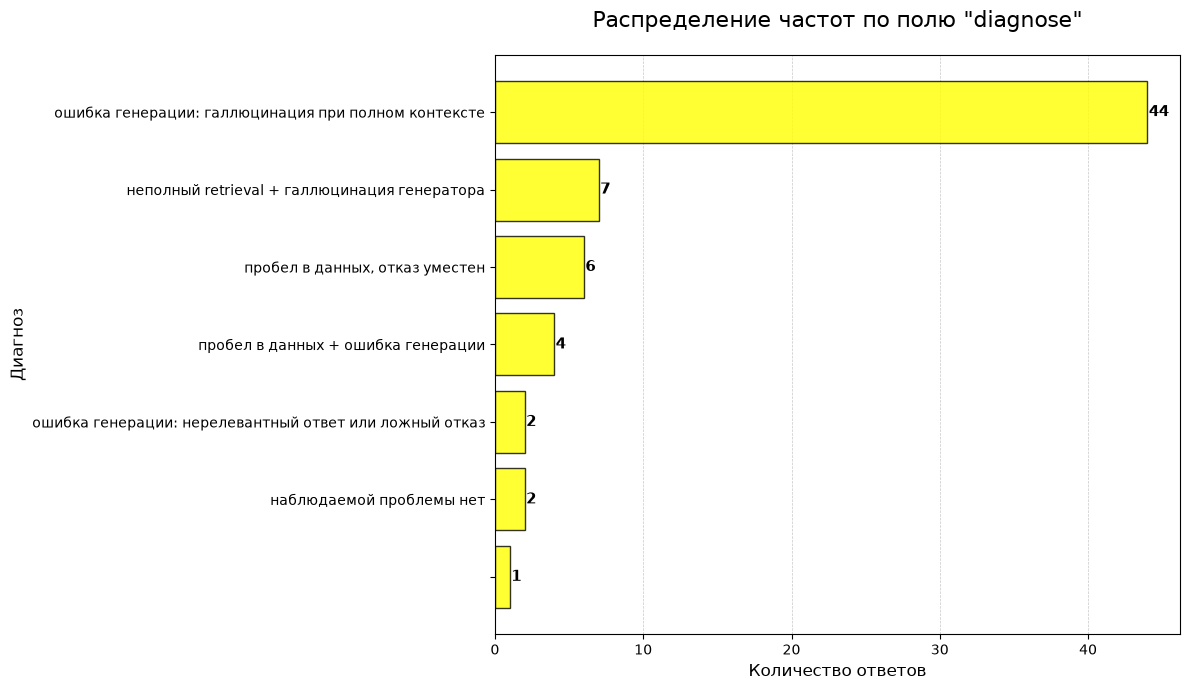

In [69]:
plot_diagnose(assessment_results)

Похоже что пайплайн больше всего страдает от ошибок генерации при полном контексте. Надо попробовать сравнить по прогону на золотом контексте по вопросам, ответ на которые есть в базе.

In [70]:
from langchain_core.documents import Document

def get_gold_chunks(vector_store, question) -> list[Document]:
    """
    Гарантированно возвращает список объектов Document по значению метаданных
    без использования плотного (векторного) поиска.
    """
    # 1. Извлекаем ID
    gold_doc_ids = list(question["relevant_docs"])

    # 2. Вызываем метод .get() у LangChain Chroma
    raw_results = vector_store.get(where={"doc_id": {"$in": gold_doc_ids}})

    # 3. Извлекаем списки текстов и метаданных
    texts = raw_results.get("documents", [])
    metadatas = raw_results.get("metadatas", [])

    # 4. Собираем из них настоящие объекты Document
    documents = []
    for text, meta in zip(texts, metadatas):
        documents.append(Document(page_content=text, metadata=meta))

    return documents

In [71]:
gold_assessment_inputs = []

non_gap_queries = [q for q in queries if q["kind"] != "gap" and q["relevant_docs"] is not None]

for i, q in enumerate(non_gap_queries, start=1):
    print(f"Подготовка ответов для оценки на золотом контексте {i} из {len(non_gap_queries)}")
    query_text = normalize_text(q["query"])

    gold_chunks = get_gold_chunks(vector_store=main_vector_store, question=q) # Получаем все релевантные чанки
    test_gold_rag_chain = create_test_rag_chain(
        llm=llm,
        prompt=prompt,
        golden_documents=gold_chunks,
        context_formatter_func=generate_context_from_chunks # Передаем функцию сортировки
    )

    query_retrieved_context = generate_context_from_chunks(gold_chunks)

    answer = test_gold_rag_chain.invoke(query_text)

    gold_assessment_inputs.append({
        "query_text": query_text,
        "query_retrieved_context": query_retrieved_context,
        "query_retrieved_doc_ids": q["relevant_docs"],
        "query_relevant_docs": q["relevant_docs"],
        "answer": answer,
        "gold_answer": q["gold"],
        "query_kind": q["kind"]
    })

Подготовка ответов для оценки на золотом контексте 1 из 56
Подготовка ответов для оценки на золотом контексте 2 из 56
Подготовка ответов для оценки на золотом контексте 3 из 56
Подготовка ответов для оценки на золотом контексте 4 из 56
Подготовка ответов для оценки на золотом контексте 5 из 56
Подготовка ответов для оценки на золотом контексте 6 из 56
Подготовка ответов для оценки на золотом контексте 7 из 56
Подготовка ответов для оценки на золотом контексте 8 из 56
Подготовка ответов для оценки на золотом контексте 9 из 56
Подготовка ответов для оценки на золотом контексте 10 из 56
Подготовка ответов для оценки на золотом контексте 11 из 56
Подготовка ответов для оценки на золотом контексте 12 из 56
Подготовка ответов для оценки на золотом контексте 13 из 56
Подготовка ответов для оценки на золотом контексте 14 из 56
Подготовка ответов для оценки на золотом контексте 15 из 56
Подготовка ответов для оценки на золотом контексте 16 из 56
Подготовка ответов для оценки на золотом контекст

In [72]:
gold_assessment_results = []
for i, input_data in enumerate(gold_assessment_inputs, start=1):
    print(f"Оценка судьи на золотом ответе {i} из {len(gold_assessment_inputs)}")
    assessment_result = assess_response(input_data=input_data)
    gold_assessment_results.append(assessment_result)

Оценка судьи на золотом ответе 1 из 56
Оценка судьи на золотом ответе 2 из 56
Оценка судьи на золотом ответе 3 из 56
Оценка судьи на золотом ответе 4 из 56
Оценка судьи на золотом ответе 5 из 56
Оценка судьи на золотом ответе 6 из 56
Оценка судьи на золотом ответе 7 из 56
Оценка судьи на золотом ответе 8 из 56
Оценка судьи на золотом ответе 9 из 56
Оценка судьи на золотом ответе 10 из 56
Оценка судьи на золотом ответе 11 из 56
Оценка судьи на золотом ответе 12 из 56
Оценка судьи на золотом ответе 13 из 56
Оценка судьи на золотом ответе 14 из 56
Оценка судьи на золотом ответе 15 из 56
Оценка судьи на золотом ответе 16 из 56
Оценка судьи на золотом ответе 17 из 56
Оценка судьи на золотом ответе 18 из 56
Оценка судьи на золотом ответе 19 из 56
Оценка судьи на золотом ответе 20 из 56
Оценка судьи на золотом ответе 21 из 56
Оценка судьи на золотом ответе 22 из 56
Оценка судьи на золотом ответе 23 из 56
Оценка судьи на золотом ответе 24 из 56
Оценка судьи на золотом ответе 25 из 56
Оценка су

Получаем ожидаемо высокий full_coverage (56 при 56 вопросах). При этом низкие `correctness` и `faithfulness`. Посмотрим распределение диагнозов.

Попробуем получить статистику основного пайплайна по вопросам, ответ на которые есть в базе.

In [74]:
non_gap_queries_assessment_inputs = []

for i, q in enumerate(non_gap_queries, start=1): # <-- Только по вопросам, ответ на которые есть в базе (для честного сравнения)
    print(f"Подготовка ответов для оценки {i} из {len(non_gap_queries)}")
    query_text = normalize_text(q["query"])
    chunks = rerank_retriever.retrieve(query_text, top_k=5) # Получаем чанки тем же методом, что и пайплайн
    query_retrieved_context = generate_context_from_chunks([chunk.doc for chunk in chunks])
    answer = rag_chain.invoke(query_text)

    non_gap_queries_assessment_inputs.append({
        "query_text": query_text,
        "query_retrieved_context": query_retrieved_context,
        "query_retrieved_doc_ids": [chunk.doc.metadata.get('doc_id') for chunk in chunks],
        "query_relevant_docs": q["relevant_docs"],
        "answer": answer,
        "gold_answer": q["gold"],
        "query_kind": q["kind"]
    })

Подготовка ответов для оценки 1 из 56
Подготовка ответов для оценки 2 из 56
Подготовка ответов для оценки 3 из 56
Подготовка ответов для оценки 4 из 56
Подготовка ответов для оценки 5 из 56
Подготовка ответов для оценки 6 из 56
Подготовка ответов для оценки 7 из 56
Подготовка ответов для оценки 8 из 56
Подготовка ответов для оценки 9 из 56
Подготовка ответов для оценки 10 из 56
Подготовка ответов для оценки 11 из 56
Подготовка ответов для оценки 12 из 56
Подготовка ответов для оценки 13 из 56
Подготовка ответов для оценки 14 из 56
Подготовка ответов для оценки 15 из 56
Подготовка ответов для оценки 16 из 56
Подготовка ответов для оценки 17 из 56
Подготовка ответов для оценки 18 из 56
Подготовка ответов для оценки 19 из 56
Подготовка ответов для оценки 20 из 56
Подготовка ответов для оценки 21 из 56
Подготовка ответов для оценки 22 из 56
Подготовка ответов для оценки 23 из 56
Подготовка ответов для оценки 24 из 56
Подготовка ответов для оценки 25 из 56
Подготовка ответов для оценки 26 и

In [75]:
non_gap_queries_assessment_results = []
for i, input_data in enumerate(non_gap_queries_assessment_inputs, start=1):
    print(f"Оценка судьи {i} из {len(non_gap_queries_assessment_inputs)}")
    assessment_result = assess_response(input_data=input_data)
    non_gap_queries_assessment_results.append(assessment_result)

Оценка судьи 1 из 56
Оценка судьи 2 из 56
Оценка судьи 3 из 56
Оценка судьи 4 из 56
Оценка судьи 5 из 56
Оценка судьи 6 из 56
Оценка судьи 7 из 56
Оценка судьи 8 из 56
Оценка судьи 9 из 56
Оценка судьи 10 из 56
Оценка судьи 11 из 56
Оценка судьи 12 из 56
Оценка судьи 13 из 56
Оценка судьи 14 из 56
Оценка судьи 15 из 56
Оценка судьи 16 из 56
Оценка судьи 17 из 56
Оценка судьи 18 из 56
Оценка судьи 19 из 56
Оценка судьи 20 из 56
Оценка судьи 21 из 56
Оценка судьи 22 из 56
Оценка судьи 23 из 56
Оценка судьи 24 из 56
Оценка судьи 25 из 56
Оценка судьи 26 из 56
Оценка судьи 27 из 56
Оценка судьи 28 из 56
Оценка судьи 29 из 56
Оценка судьи 30 из 56
Оценка судьи 31 из 56
Оценка судьи 32 из 56
Оценка судьи 33 из 56
Оценка судьи 34 из 56
Оценка судьи 35 из 56
Оценка судьи 36 из 56
Оценка судьи 37 из 56
Оценка судьи 38 из 56
Оценка судьи 39 из 56
Оценка судьи 40 из 56
Оценка судьи 41 из 56
Оценка судьи 42 из 56
Оценка судьи 43 из 56
Оценка судьи 44 из 56
Оценка судьи 45 из 56
Оценка судьи 46 из 

Посмотрим статистику по золотому контексту и обычному пайплайну на одних и тех же запросах

In [76]:
summarize_rag_results(gold_assessment_results)

,Средний faithfulness,Средний gold answer adherence,Средний correctness,Количество ответов ниже порога 4 по faithfulness,"Отказы с relevance < 3, исключая уместные (proper refusals)",есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка,full_coverage,Сколько уместных отказов,Сколько ложных отказов
0,2.39,2.75,0.39,49,26,56,56,0,1


Получаем ожидаемо высокий full_coverage (56/56). При этом низкие `correctness` и `faithfulness`.

In [77]:
summarize_rag_results(non_gap_queries_assessment_results)

,Средний faithfulness,Средний gold answer adherence,Средний correctness,Количество ответов ниже порога 4 по faithfulness,"Отказы с relevance < 3, исключая уместные (proper refusals)",есть ответ в базе (not gap) И поиск выдал >= 1 нужного чанка,full_coverage,Сколько уместных отказов,Сколько ложных отказов
0,2.11,2.43,0.32,52,31,56,48,0,3


Здесь тоже видим низкие `correctness` и `faithfulness`. Full coverage при этом на уровне 48/56, что примерно соответствует нашему `recall@5>0.9`

Сравним диагнозы на золотом контексте и на обычном на одних и тех же вопросах.

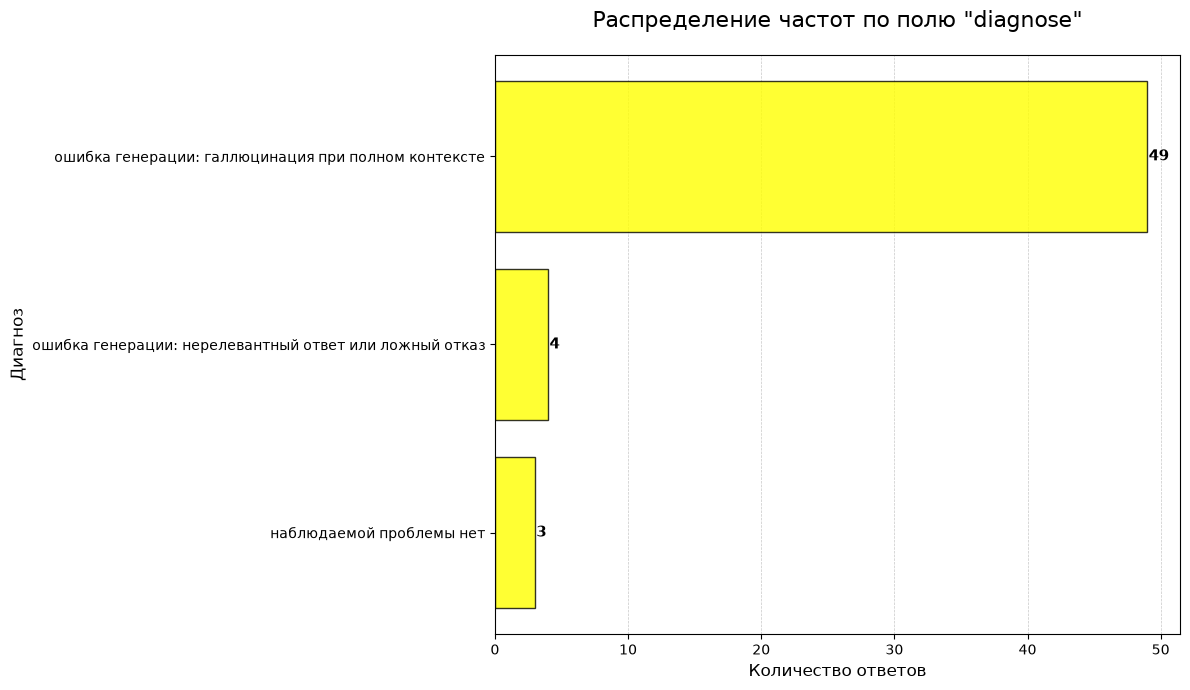

In [78]:
plot_diagnose(gold_assessment_results)

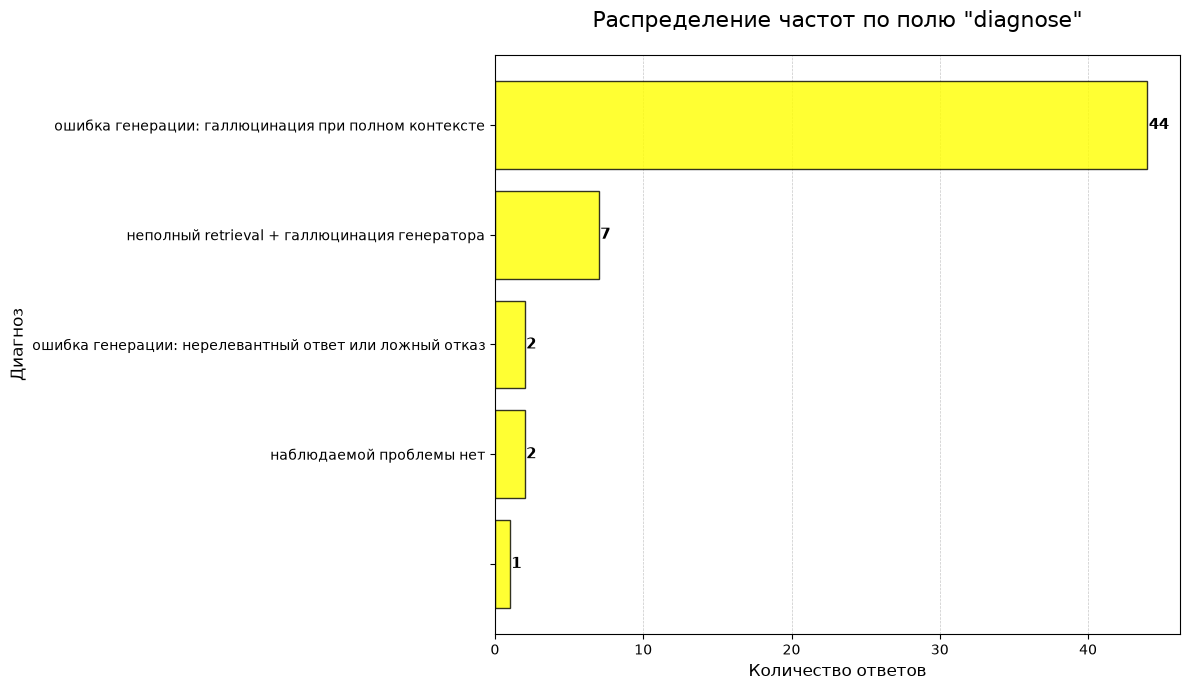

In [79]:
plot_diagnose(non_gap_queries_assessment_results)

# Выводы

Пайплайн страдает от галлюцинаций модели при полном контексте. Поскольку промпт уже был заземлён, а `temperature = 0`, остаётся только рассмотреть более тяжёлую плотную модель.

Готовность к пилоту:
1. Целевая метрика `recall@5 >= 0,85` была уверенно достигнута
2. Целевая метрика `correctness >= 0,90` не была достигнута по причинам описанным выше

Итоговая рекомендация: рассмотреть другие модели, лучше обученные на русскоязычных текстах.